# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions, plot_date_range
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/commercial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # Hour frequency
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 2.0  # For commercial data

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_com_hour_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 2 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 2 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.04 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
train[0][0]

array([[Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub1', 22.0, ..., 0.625, 0.6275000000000546, 0.621818181818195],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub3', 22.0, ..., 0.31666666666660603, 0.32416666666669397,
        0.3072727272727372],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub2', 22.0, ..., 0.004166666666662877, 0.0033333333333303017,
        0.003636363636370664],
       ...,
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub2', 21.0, ..., 0.004166666666662877, 0.004166666666662877,
        0.0033333333333397754],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub1', 21.0, ..., 0.5883333333334425, 0.6208333333330908,
        0.6091666666667758],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub3', 21.0, ..., 0.3674999999999879, 0.37333333333344854,
        0.3758333333333515]], shape=(2016, 9

In [7]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 2 splits
Validation data: 2 splits
First train split shape: X=(2016, 9), y=(2016,)
First valid split shape: X=(2016, 9), y=(2016,)

Memory usage:
Train: 0.46 MB
Valid: 0.21 MB
Test: 0.09 MB
Total: 0.77 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (predict previous value)

In [8]:
update_freq = "1H"
baseline = PreviousValueRegressor
baseline_params = {}

In [9]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=baseline,
    model_params=baseline_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000420 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0601
	MAE: 0.0335
	MAPE: 258.9494%

Directional Metrics:
	Directional Accuracy: 42.1759%
	First-Diff Correlation: 0.1024

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9925
		F1: 0.9962
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000397 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0556
	MAE: 0.0292
	MAPE: 228.5929%

Directional Metrics:
	Directional Accuracy: 40.1575%
	First-Diff Correlation: 0.1059

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [10]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0578 ± 0.0023
	MAE: 0.0313 ± 0.0022
	MAPE: 243.7712% ± 15.1782%

	Directional Metrics:
		Directional Accuracy: 41.1667% ± 1.0092%
		First-Diff Correlation: 0.1042 ± 0.0018

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 1.0000 ± 0.0000
		Spike F1: 1.0000 ± 0.0000
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9962 ± 0.0038
		Drop F1: 0.9981 ± 0.0019
Daily Metrics:
	RMSE: 0.0778 ± 0.0110
	MAE: 0.0468 ± 0.0070
	MAPE: 3.5903% ± 0.5330%

	Directional Metrics:
		Directional Accuracy: 98.1481% ± 1.8519%
		First-Diff Correlation: 0.9631 ± 0.0148

	Immediate Detection (delta=0):
		Spi

#### Validation plots

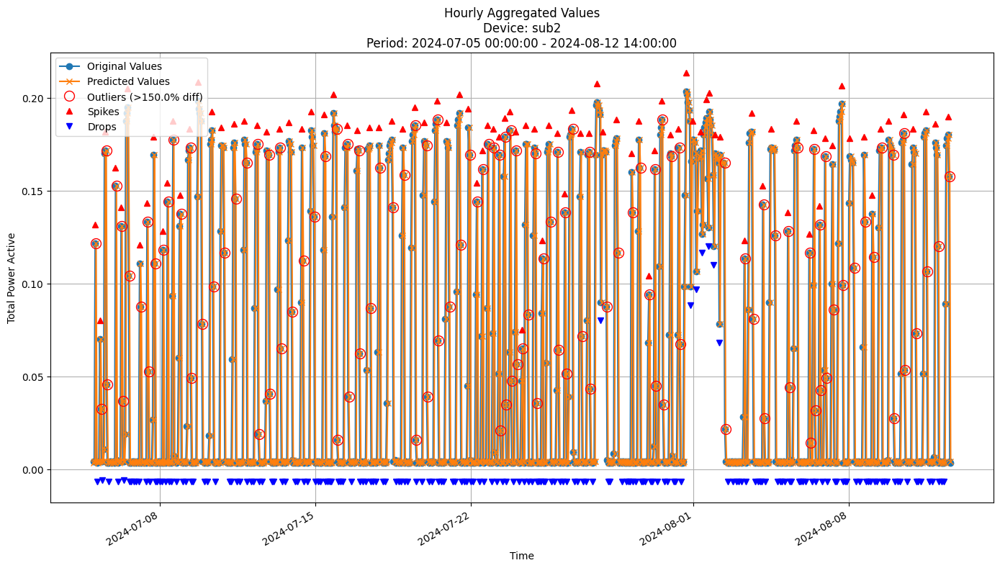


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0589
MAE: 0.0323
MAPE: 250.5989%

Directional Metrics:
Directional Accuracy: 41.5767%
First-Diff Correlation: 0.1033

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 0.9947
  F1 Score: 0.9973


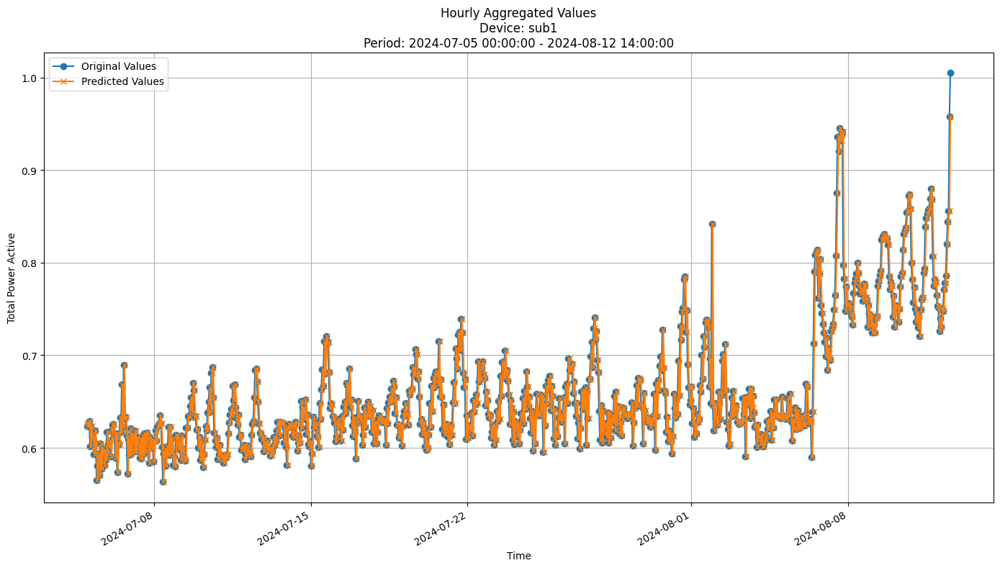


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0250
MAE: 0.0181
MAPE: 2.7465%

Directional Metrics:
Directional Accuracy: 37.0410%
First-Diff Correlation: -0.1352

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


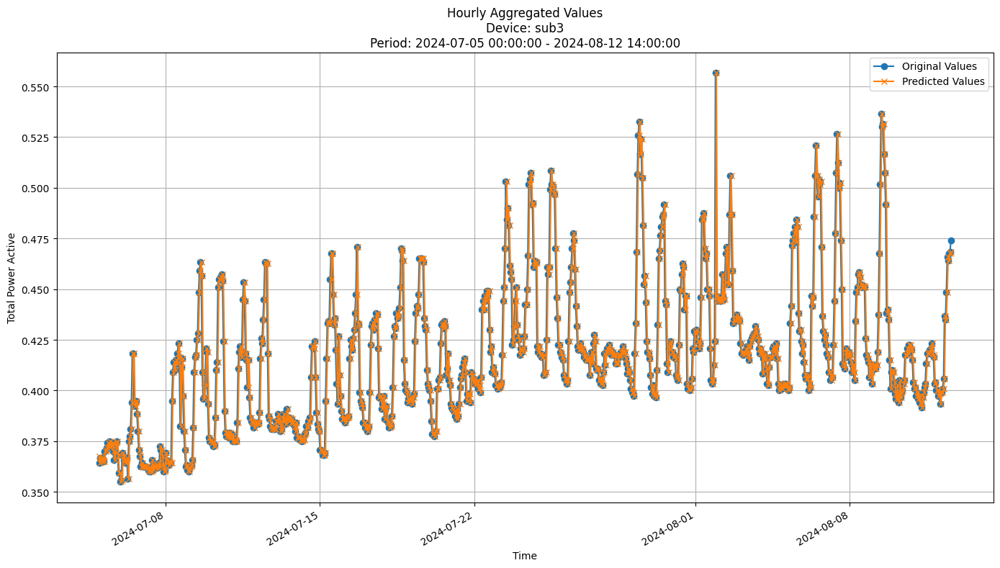


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0128
MAE: 0.0072
MAPE: 1.6742%

Directional Metrics:
Directional Accuracy: 51.0799%
First-Diff Correlation: 0.2412

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [11]:
join_periods = [-1, -2]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [12]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
# gbdt_params = {
#     'n_estimators': 100,
#     'learning_rate': 0.03,
#     'subsample': 0.8,
#     'max_depth': 10,
#     'random_state': 42
# }
gbdt_params = {'n_estimators': 100, 
 'learning_rate': 0.05, 
 'max_depth': 3, 
 'subsample': 0.6, 
 'random_state': 42}

In [13]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.08 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.09 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0642
	MAE: 0.0479
	MAPE: 453.7181%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: 0.2460

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1286
		Recall: 0.1250
		F1: 0.1268
	Drops:
		Precision: 0.2609
		Recall: 0.1353
		F1: 0.1782

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.13 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.010620 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1041
	MAE: 0.0930
	MAPE: 2058.9708%

Directional Metrics:
	Directional Accuracy: 51.1811%
	First-Diff Correlation: 0.0578

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.2083
		F1: 0.1852
	Drops:
		Precision: 0.3103
		Recall: 0.1698
		F1: 0.2195

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4000
		Recall: 0.5000
		F1: 0.4444
	Drops:
		Precision: 0.6552
		Recall: 0.3585
		F1: 0.4634
-----------------------------------------------

#### Results

In [14]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0491 ± 0.0023
	MAE: 0.0373 ± 0.0021
	MAPE: 479.9757% ± 18.9832%

	Directional Metrics:
		Directional Accuracy: 55.0096% ± 0.8771%
		First-Diff Correlation: 0.3876 ± 0.0222

	Immediate Detection (delta=0):
		Spike Precision: 0.2309 ± 0.0277
		Spike Recall: 0.2060 ± 0.0248
		Spike F1: 0.2177 ± 0.0262
		Drop Precision: 0.2266 ± 0.0365
		Drop Recall: 0.0973 ± 0.0130
		Drop F1: 0.1361 ± 0.0193

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6360 ± 0.0019
		Spike Recall: 0.5672 ± 0.0020
		Spike F1: 0.5997 ± 0.0020
		Drop Precision: 0.7904 ± 0.0360
		Drop Recall: 0.3412 ± 0.0251
		Drop F1: 0.4766 ± 0.0310
Daily Metrics:
	RMSE: 0.2552 ± 0.0178
	MAE: 0.2021 ± 0.0133
	MAPE: 23.1114% ± 0.0082%

	Directional Metrics:
		Directional Accuracy: 45.8586% ± 1.4141%
		First-Diff Correlation: 0.3803 ± 0.1491

	Immediate Detection (delta=0):
		Sp

#### Training plots

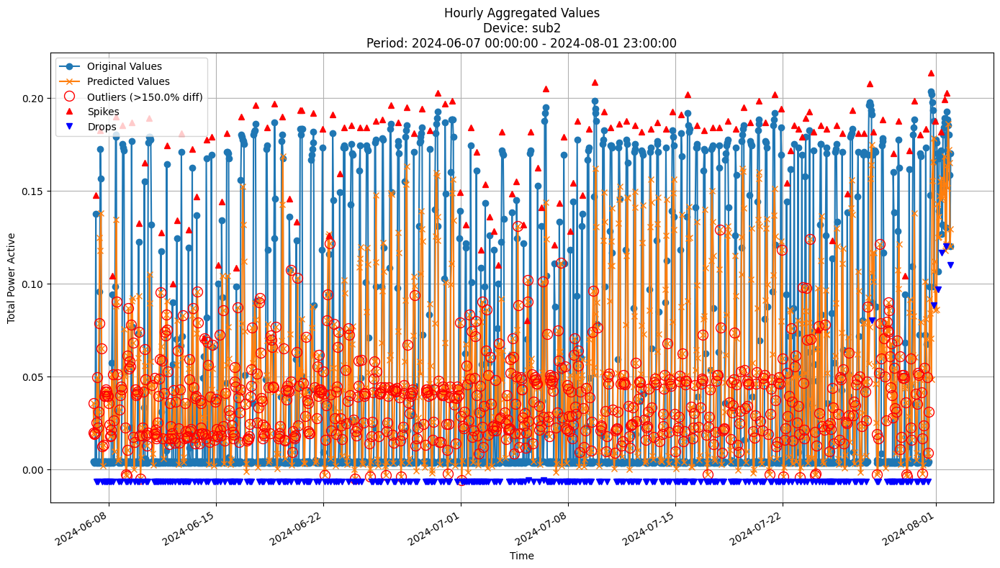


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0513
MAE: 0.0394
MAPE: 498.9588%

Directional Metrics:
Directional Accuracy: 54.1325%
First-Diff Correlation: 0.3654

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


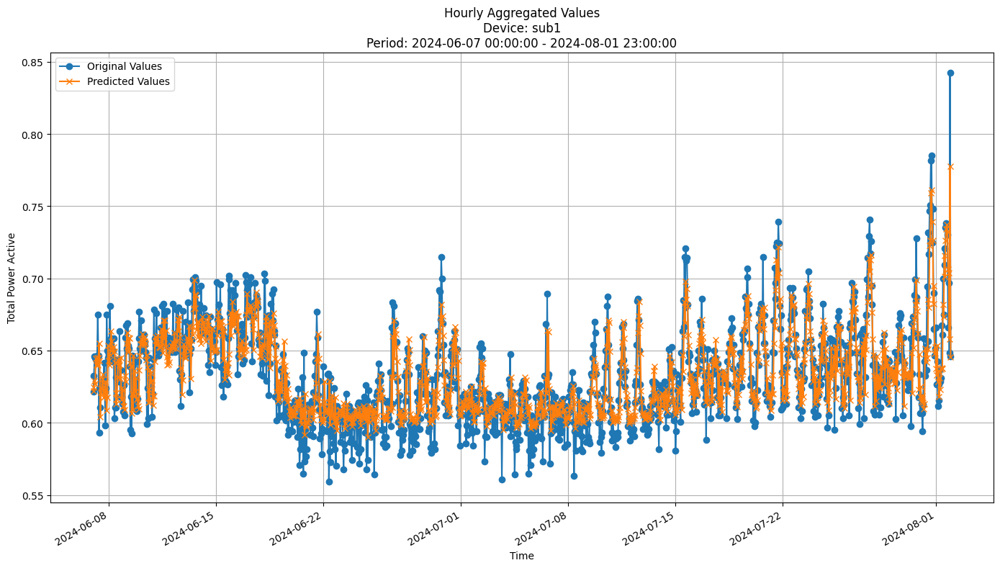


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0176
MAE: 0.0134
MAPE: 2.1227%

Directional Metrics:
Directional Accuracy: 59.0469%
First-Diff Correlation: 0.4560

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


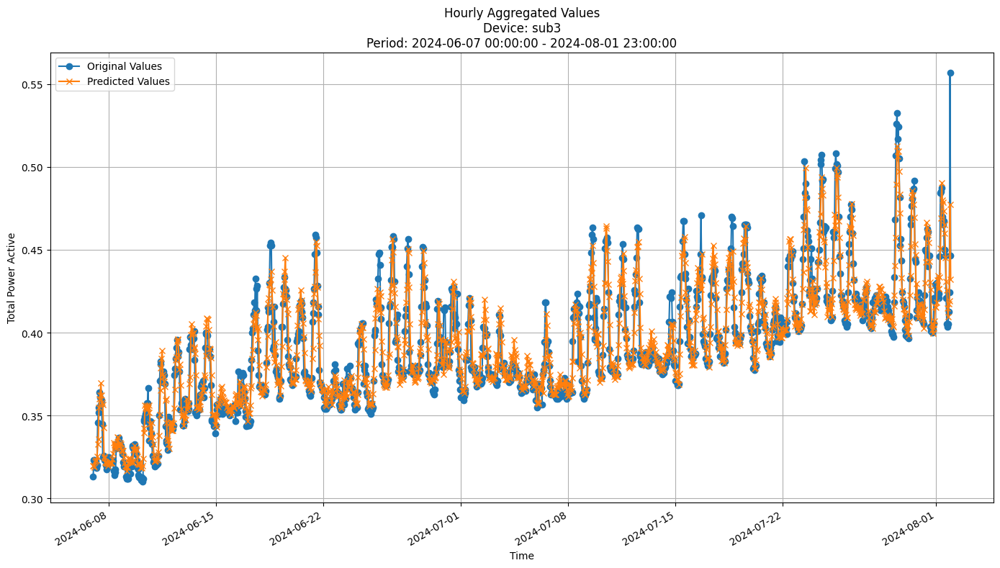


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0111
MAE: 0.0079
MAPE: 1.9810%

Directional Metrics:
Directional Accuracy: 57.7811%
First-Diff Correlation: 0.4259

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

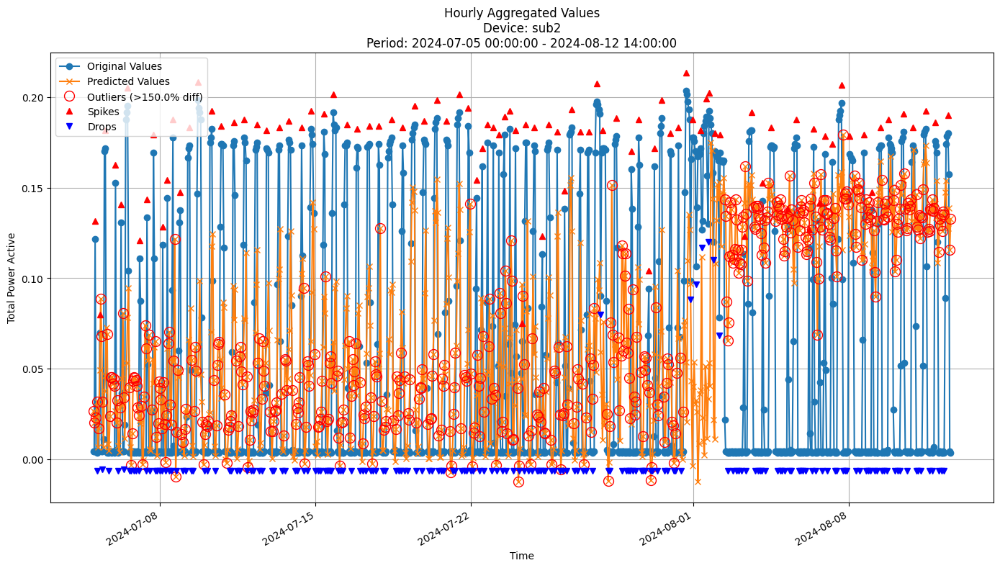


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0773
MAE: 0.0603
MAPE: 895.2925%

Directional Metrics:
Directional Accuracy: 51.2959%
First-Diff Correlation: 0.2109

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


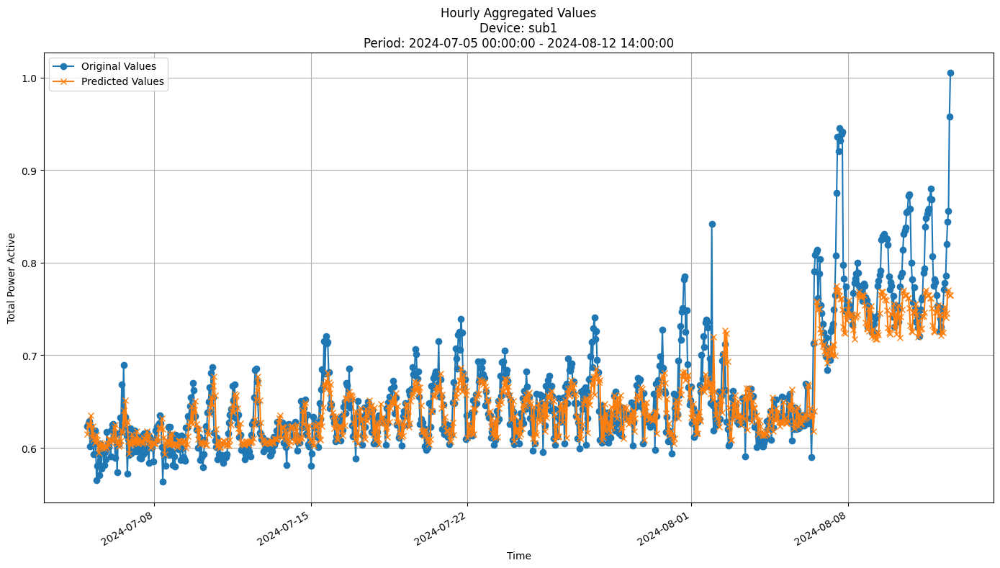


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0343
MAE: 0.0218
MAPE: 3.1087%

Directional Metrics:
Directional Accuracy: 57.5594%
First-Diff Correlation: 0.2175

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


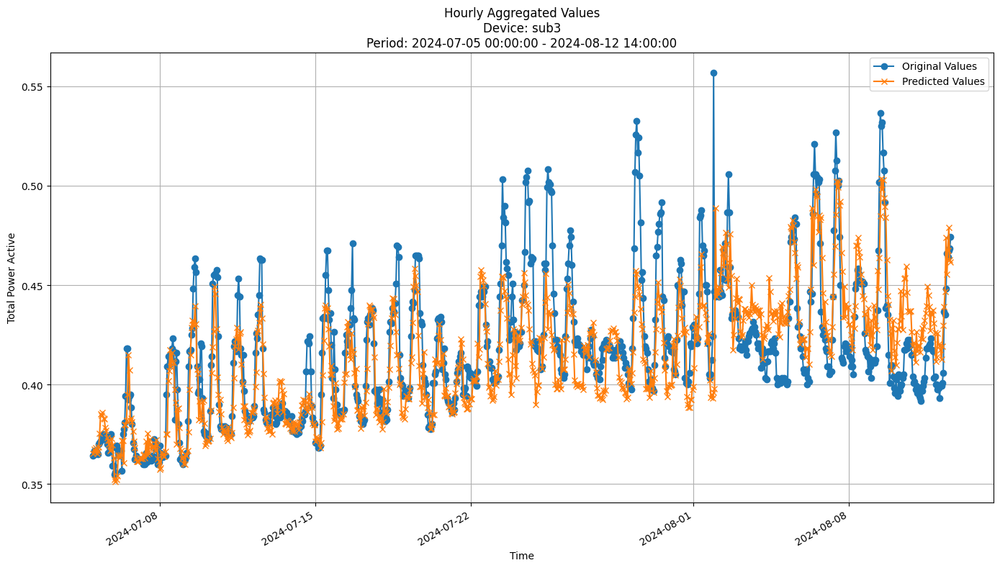


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0209
MAE: 0.0151
MAPE: 3.4802%

Directional Metrics:
Directional Accuracy: 54.2117%
First-Diff Correlation: 0.1935

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [16]:
join_periods = [-2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [17]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
# rf_params = {
#     'n_estimators': 100,
#     'max_depth': 10,
#     'max_features': 'sqrt',
#     'random_state': 42,
#     'n_jobs': -1
# }
rf_params = {'n_estimators': 300, 
 'max_depth': 7, 
 'max_features': 1.0, 
 'random_state': 42, 
 'n_jobs': -1}

In [18]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.33 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.32 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.119888 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0642
	MAE: 0.0471
	MAPE: 442.5654%

Directional Metrics:
	Directional Accuracy: 51.5648%
	First-Diff Correlation: 0.2680

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1538
		Recall: 0.1389
		F1: 0.1460
	Drops:
		Precision: 0.2969
		Recall: 0.1429
		F1: 0.1929

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.34 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.119881 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1074
	MAE: 0.0960
	MAPE: 2047.6815%

Directional Metrics:
	Directional Accuracy: 48.0315%
	First-Diff Correlation: -0.0660

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1034
		Recall: 0.1250
		F1: 0.1132
	Drops:
		Precision: 0.1724
		Recall: 0.0943
		F1: 0.1220

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2414
		Recall: 0.2917
		F1: 0.2642
	Drops:
		Precision: 0.5862
		Recall: 0.3208
		F1: 0.4146
----------------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0449 ± 0.0026
	MAE: 0.0325 ± 0.0022
	MAPE: 410.9020% ± 20.7942%

	Directional Metrics:
		Directional Accuracy: 58.1010% ± 1.0645%
		First-Diff Correlation: 0.5388 ± 0.0404

	Immediate Detection (delta=0):
		Spike Precision: 0.3639 ± 0.0747
		Spike Recall: 0.3191 ± 0.0655
		Spike F1: 0.3401 ± 0.0698
		Drop Precision: 0.3143 ± 0.0107
		Drop Recall: 0.1339 ± 0.0089
		Drop F1: 0.1878 ± 0.0107

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7243 ± 0.0301
		Spike Recall: 0.6351 ± 0.0264
		Spike F1: 0.6768 ± 0.0281
		Drop Precision: 0.7583 ± 0.0083
		Drop Recall: 0.3229 ± 0.0141
		Drop F1: 0.4528 ± 0.0153
Daily Metrics:
	RMSE: 0.2426 ± 0.0106
	MAE: 0.1924 ± 0.0043
	MAPE: 22.2740% ± 1.1805%

	Directional Metrics:
		Directional Accuracy: 51.3131% ± 6.8687%
		First-Diff Correlation: 0.4036 ± 0.1547

	Immediate Detection (delta=0):
		Sp

#### Training plots
Plot only the last period of predictions

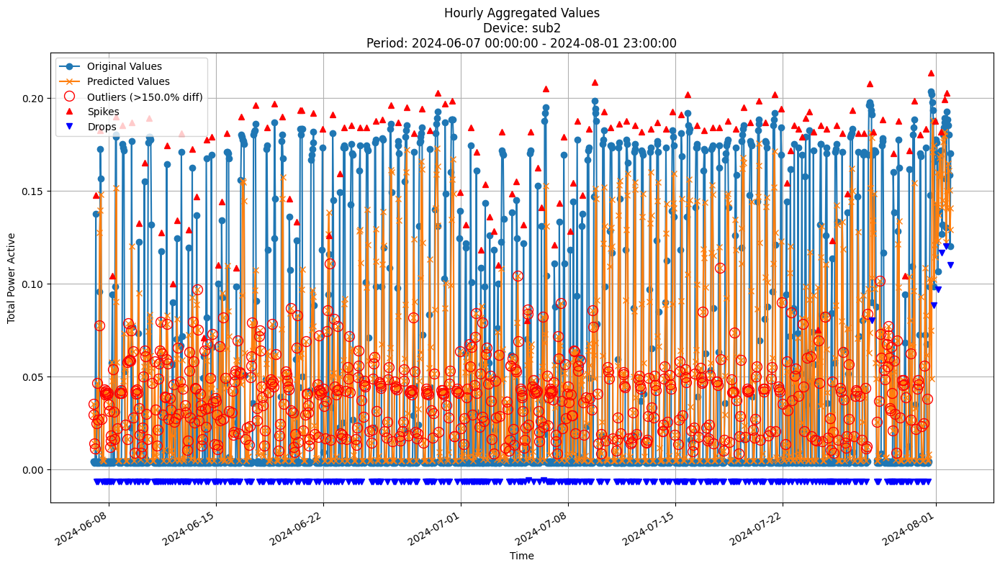


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0475
MAE: 0.0347
MAPE: 431.6961%

Directional Metrics:
Directional Accuracy: 57.0365%
First-Diff Correlation: 0.4984

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


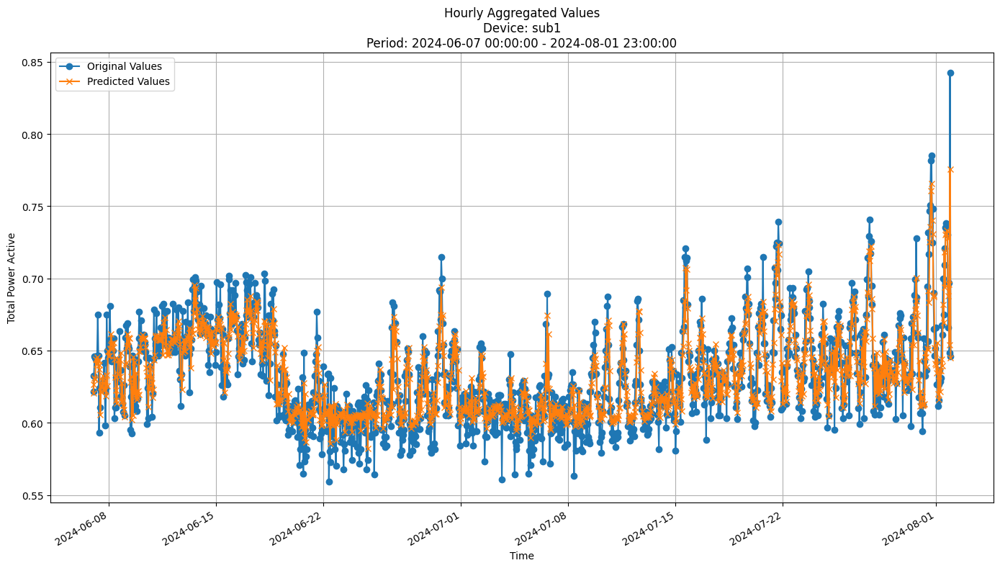


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0147
MAE: 0.0115
MAPE: 1.8142%

Directional Metrics:
Directional Accuracy: 70.2159%
First-Diff Correlation: 0.6533

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


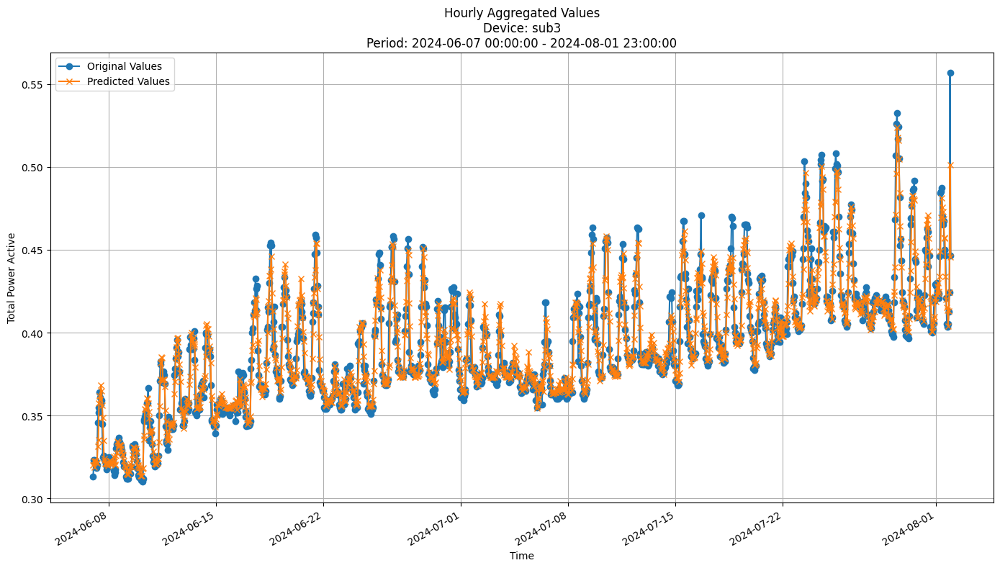


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0090
MAE: 0.0063
MAPE: 1.5700%

Directional Metrics:
Directional Accuracy: 64.1102%
First-Diff Correlation: 0.6048

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [20]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

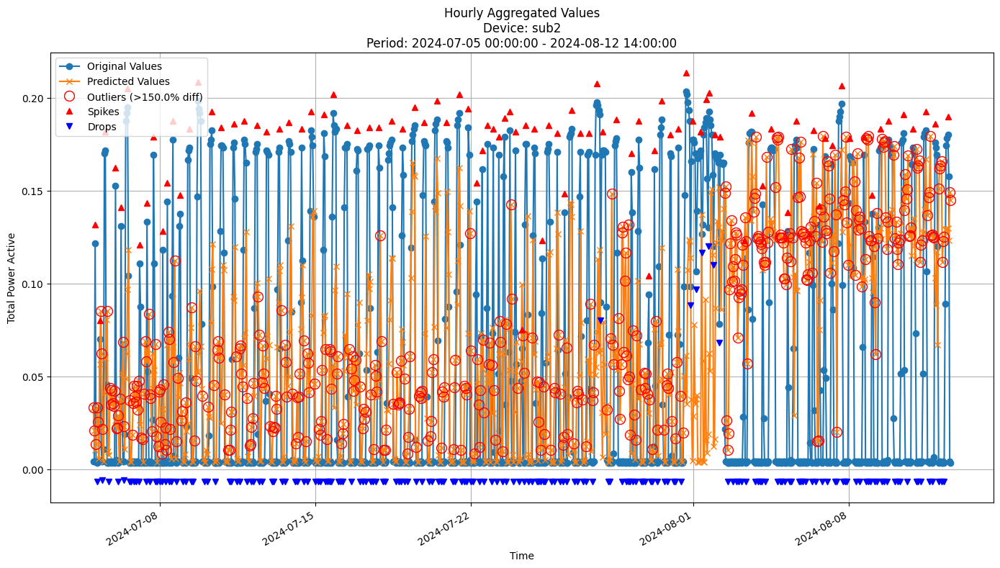


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0785
MAE: 0.0606
MAPE: 884.1022%

Directional Metrics:
Directional Accuracy: 50.5400%
First-Diff Correlation: 0.1871

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


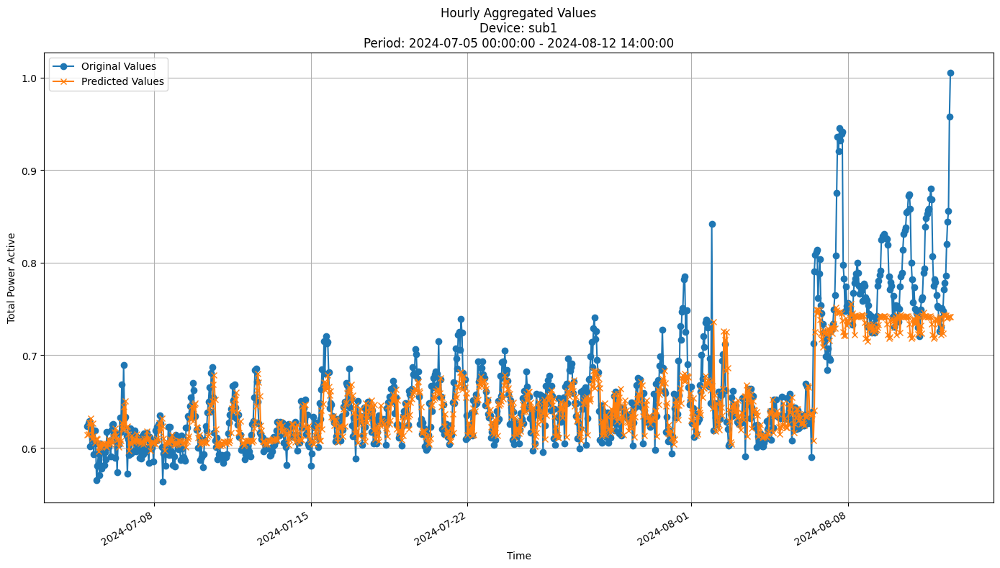


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0375
MAE: 0.0233
MAPE: 3.3054%

Directional Metrics:
Directional Accuracy: 55.8315%
First-Diff Correlation: 0.1771

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


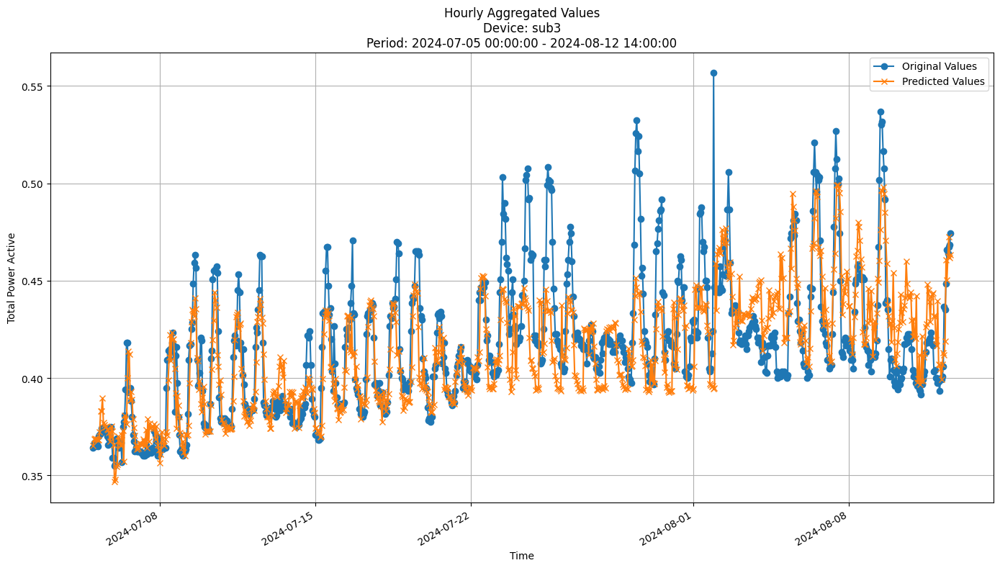


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0223
MAE: 0.0162
MAPE: 3.7512%

Directional Metrics:
Directional Accuracy: 54.9676%
First-Diff Correlation: 0.1742

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [21]:
join_periods = [-2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [22]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
# hoef_params = {
#     'grace_period': 10,
#     'delta': 0.5,
#     'max_depth': 10,
#     'tau': 0.05,
#     'leaf_prediction': 'mean'
# }
hoef_params = {'max_depth': 10,
'grace_period': 96,
'tau': 0.001,
'delta': 0.005}

In [23]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.130547 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0697
	MAE: 0.0527
	MAPE: 461.2439%

Directional Metrics:
	Directional Accuracy: 44.8584%
	First-Diff Correlation: 0.1376

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0580
		Recall: 0.0556
		F1: 0.0567
	Drops:
		Precision: 0.1429
		Recall: 0.0752
		F1: 0.0985

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5072
		Recall: 0.4861
		F1: 0.4965
	Drops:
		Precision: 0.5286
		Recall: 0.2782
		F1: 0.3645
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.142982 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0729
	MAE: 0.0599
	MAPE: 770.4643%

Directional Metrics:
	Directional Accuracy: 40.5512%
	First-Diff Correlation: 0.0363

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1333
		Recall: 0.0377
		F1: 0.0588

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2143
		Recall: 0.1250
		F1: 0.1579
	Drops:
		Precision: 0.4667
		Recall: 0.1321
		F1: 0.2059
--------------------------------------------------
Dai

#### Results

In [24]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0635 ± 0.0013
	MAE: 0.0483 ± 0.0023
	MAPE: 557.8019% ± 32.3045%

	Directional Metrics:
		Directional Accuracy: 16.9452% ± 2.0421%
		First-Diff Correlation: 0.0829 ± 0.0104

	Immediate Detection (delta=0):
		Spike Precision: 0.0821 ± 0.0821
		Spike Recall: 0.0797 ± 0.0797
		Spike F1: 0.0809 ± 0.0809
		Drop Precision: 0.1716 ± 0.1716
		Drop Recall: 0.0842 ± 0.0842
		Drop F1: 0.1130 ± 0.1130

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2612 ± 0.2612
		Spike Recall: 0.2536 ± 0.2536
		Spike F1: 0.2574 ± 0.2574
		Drop Precision: 0.3507 ± 0.3507
		Drop Recall: 0.1722 ± 0.1722
		Drop F1: 0.2310 ± 0.2310
Daily Metrics:
	RMSE: 0.4110 ± 0.0560
	MAE: 0.2966 ± 0.0022
	MAPE: 28.6080% ± 2.0774%

	Directional Metrics:
		Directional Accuracy: 31.9865% ± 13.4680%
		First-Diff Correlation: -0.2346 ± 0.3395

	Immediate Detection (delta=0):
		

#### Training plots
Plot only the last period of predictions

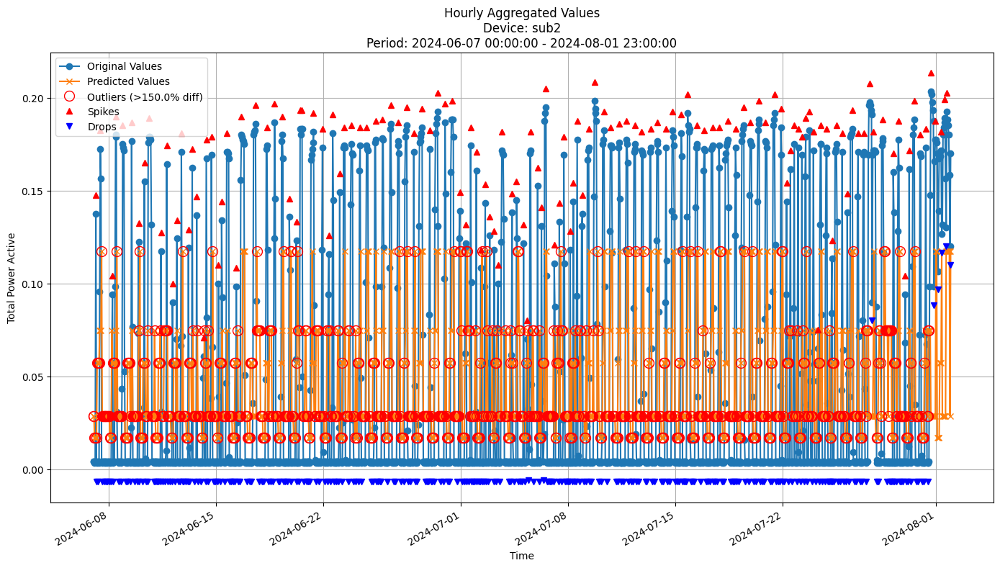


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0649
MAE: 0.0505
MAPE: 590.1064%

Directional Metrics:
Directional Accuracy: 18.9873%
First-Diff Correlation: 0.0932

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


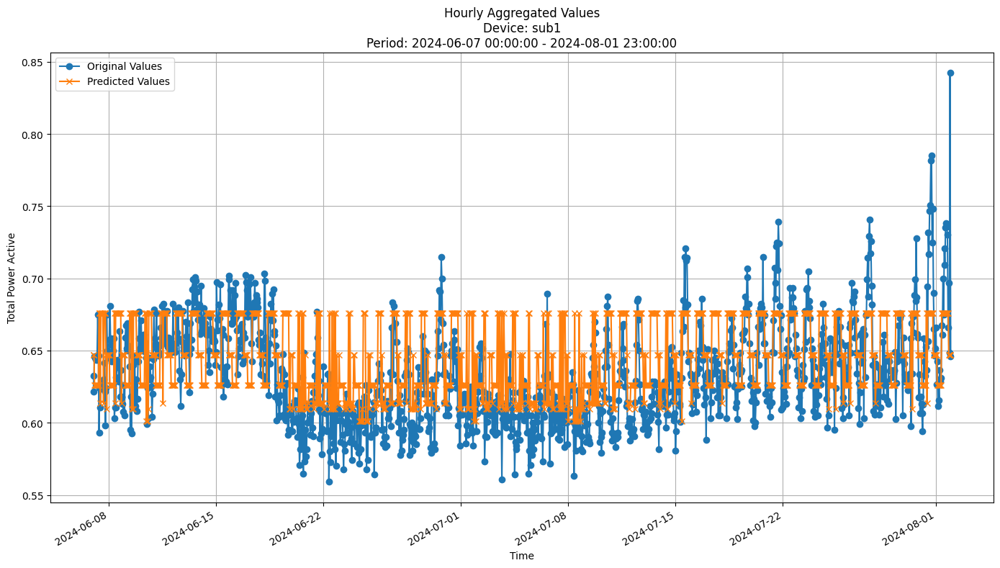


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0339
MAE: 0.0265
MAPE: 4.2211%

Directional Metrics:
Directional Accuracy: 15.4877%
First-Diff Correlation: 0.0555

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


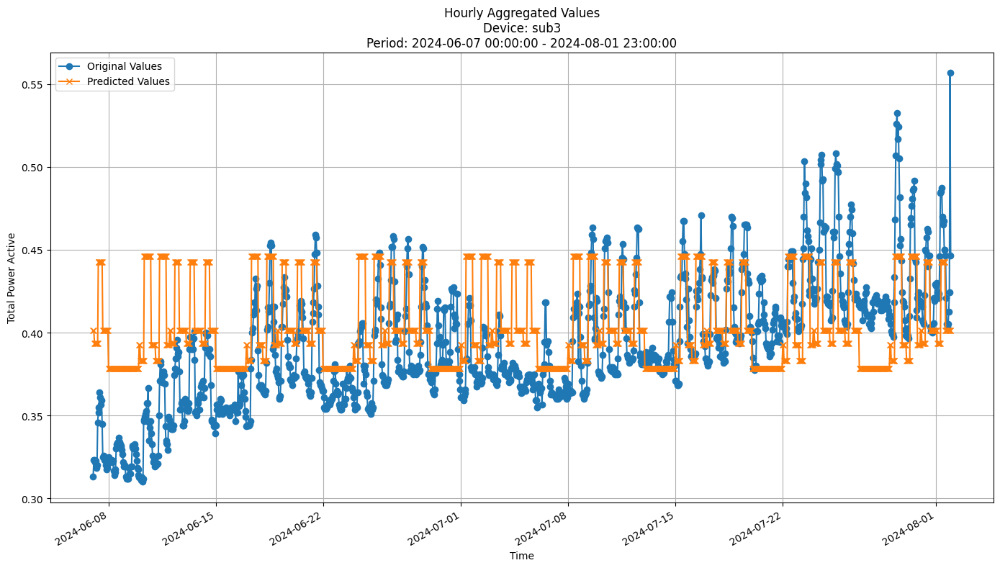


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0354
MAE: 0.0284
MAPE: 7.4567%

Directional Metrics:
Directional Accuracy: 10.9456%
First-Diff Correlation: 0.2081

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [25]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

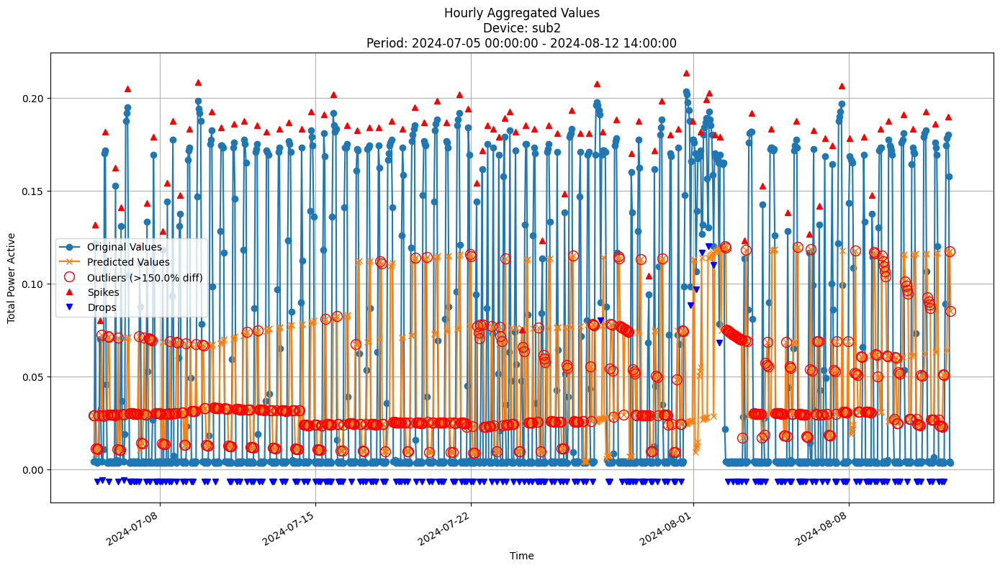


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0706
MAE: 0.0547
MAPE: 546.3045%

Directional Metrics:
Directional Accuracy: 43.6285%
First-Diff Correlation: 0.1126

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


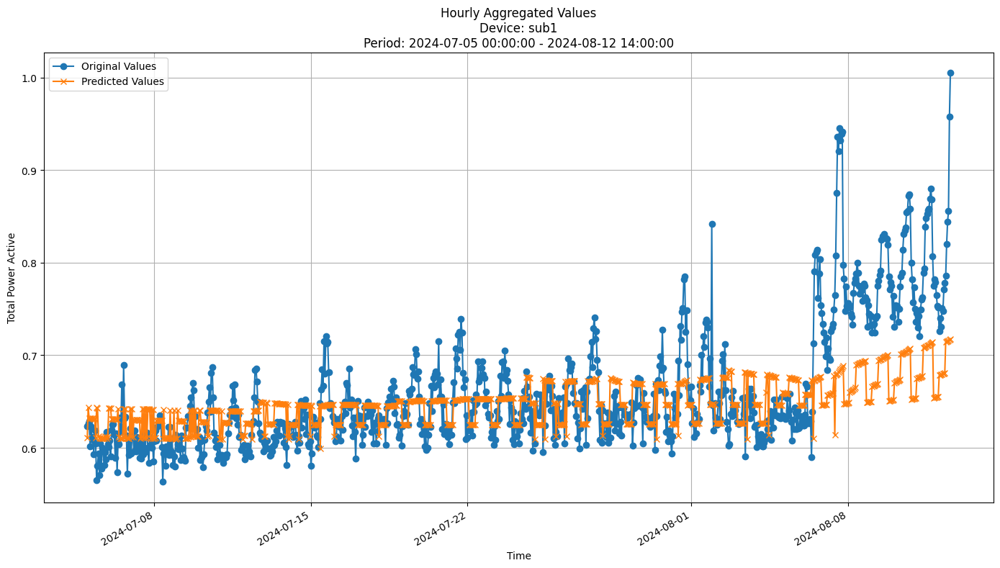


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0550
MAE: 0.0373
MAPE: 5.2794%

Directional Metrics:
Directional Accuracy: 45.4644%
First-Diff Correlation: 0.0801

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


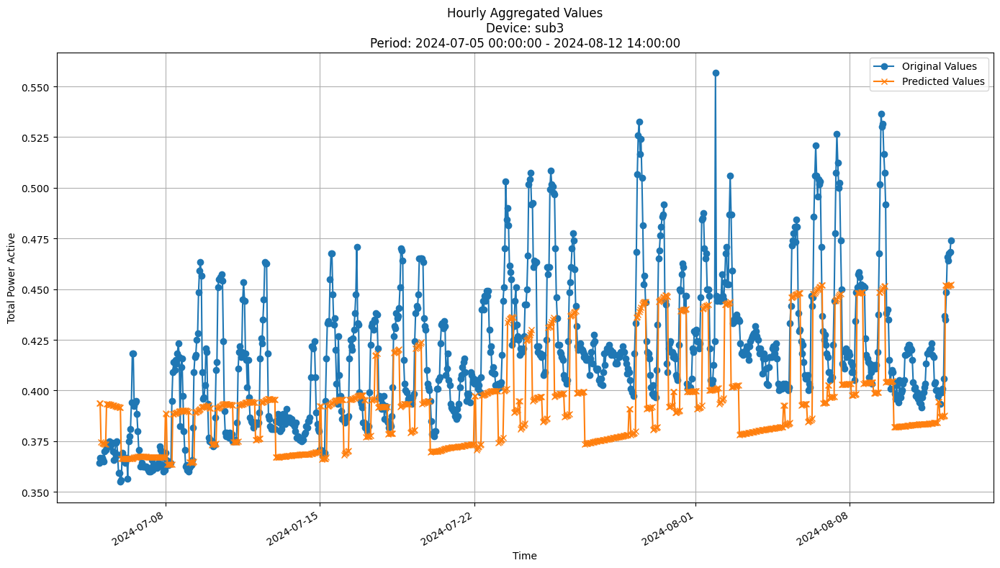


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0334
MAE: 0.0270
MAPE: 6.2454%

Directional Metrics:
Directional Accuracy: 47.8402%
First-Diff Correlation: 0.1583

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [26]:
join_periods = [-2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [27]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [28]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 2.810966 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0694
	MAE: 0.0538
	MAPE: 492.8273%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: 0.1479

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1698
		Recall: 0.1250
		F1: 0.1440
	Drops:
		Precision: 0.1731
		Recall: 0.0677
		F1: 0.0973

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5660
		Recall: 0.4167
		F1: 0.4800
	Drops:
		Precision: 0.5962
		Recall: 0.2331
		F1: 0.3351
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 3.238037 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0712
	MAE: 0.0601
	MAPE: 734.5050%

Directional Metrics:
	Directional Accuracy: 45.2756%
	First-Diff Correlation: 0.0013

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0870
		Recall: 0.0833
		F1: 0.0851
	Drops:
		Precision: 0.1364
		Recall: 0.0566
		F1: 0.0800

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3043
		Recall: 0.2917
		F1: 0.2979
	Drops:
		Precision: 0.5000
		Recall: 0.2075
		F1: 0.2933
--------------------------------------------------
Dai

#### Results

In [29]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0601 ± 0.0023
	MAE: 0.0477 ± 0.0031
	MAPE: 612.4790% ± 32.4450%

	Directional Metrics:
		Directional Accuracy: 48.7894% ± 0.5032%
		First-Diff Correlation: 0.2180 ± 0.0122

	Immediate Detection (delta=0):
		Spike Precision: 0.1513 ± 0.0032
		Spike Recall: 0.1231 ± 0.0001
		Spike F1: 0.1358 ± 0.0013
		Drop Precision: 0.2679 ± 0.0564
		Drop Recall: 0.1064 ± 0.0255
		Drop F1: 0.1523 ± 0.0352

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5002 ± 0.0184
		Spike Recall: 0.4074 ± 0.0234
		Spike F1: 0.4490 ± 0.0216
		Drop Precision: 0.7290 ± 0.0367
		Drop Recall: 0.2880 ± 0.0233
		Drop F1: 0.4128 ± 0.0299
Daily Metrics:
	RMSE: 0.3717 ± 0.0982
	MAE: 0.2653 ± 0.0251
	MAPE: 28.6777% ± 0.2981%

	Directional Metrics:
		Directional Accuracy: 49.4949% ± 5.0505%
		First-Diff Correlation: 0.3754 ± 0.0987

	Immediate Detection (delta=0):
		Sp

#### Training plots

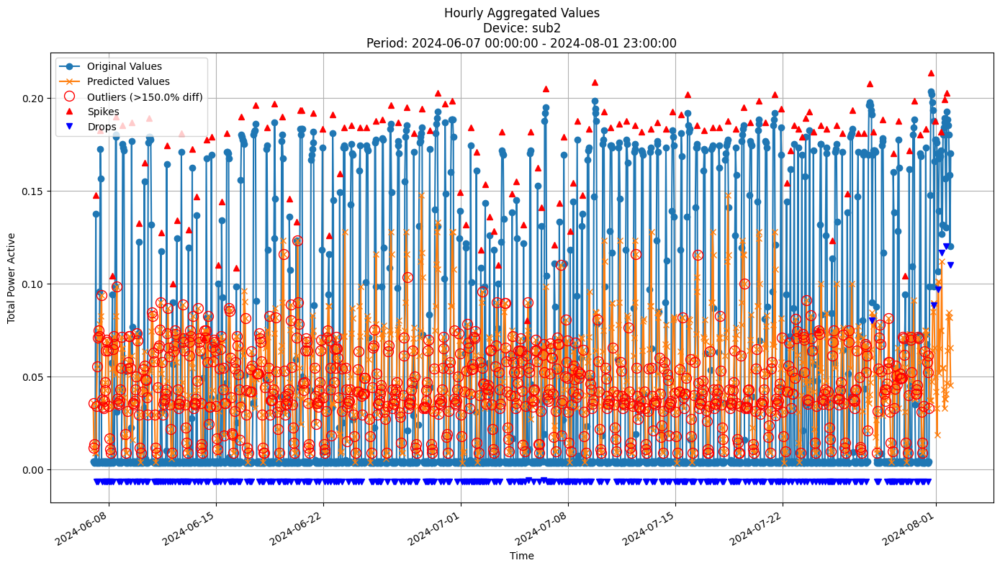


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0624
MAE: 0.0508
MAPE: 644.9240%

Directional Metrics:
Directional Accuracy: 49.2926%
First-Diff Correlation: 0.2057

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


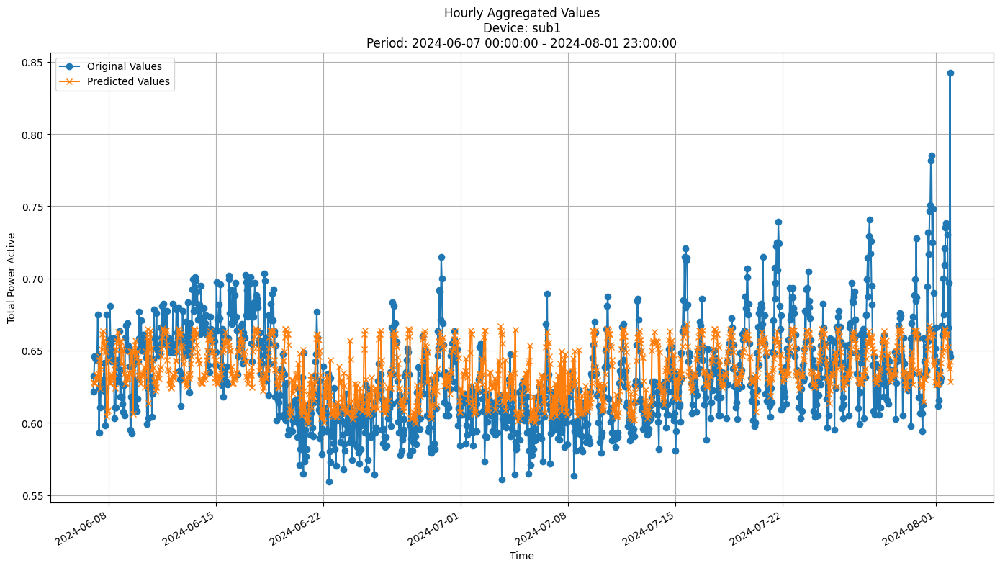


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0280
MAE: 0.0214
MAPE: 3.3663%

Directional Metrics:
Directional Accuracy: 52.1966%
First-Diff Correlation: 0.1467

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


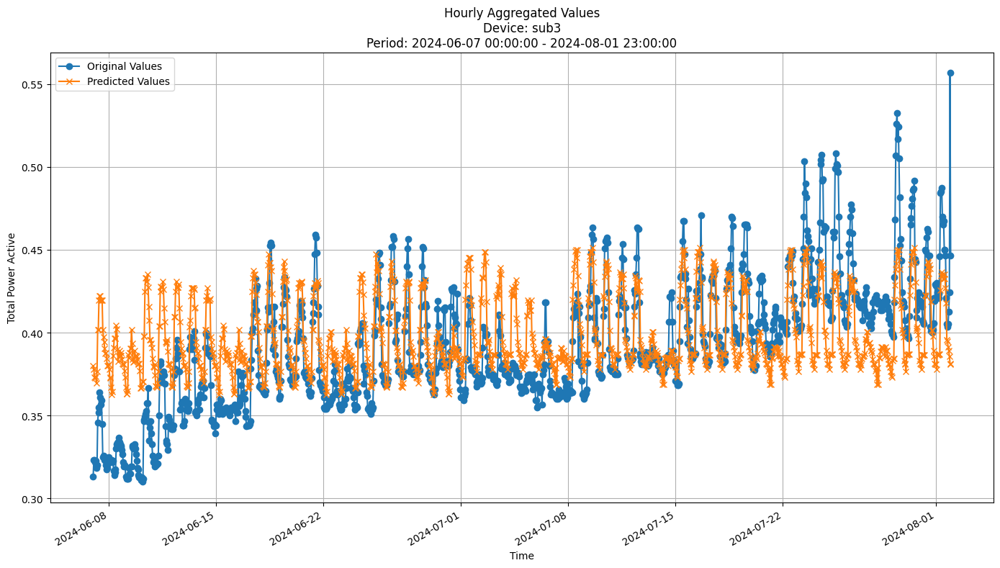


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0301
MAE: 0.0237
MAPE: 6.1876%

Directional Metrics:
Directional Accuracy: 51.0052%
First-Diff Correlation: 0.3931

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [30]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

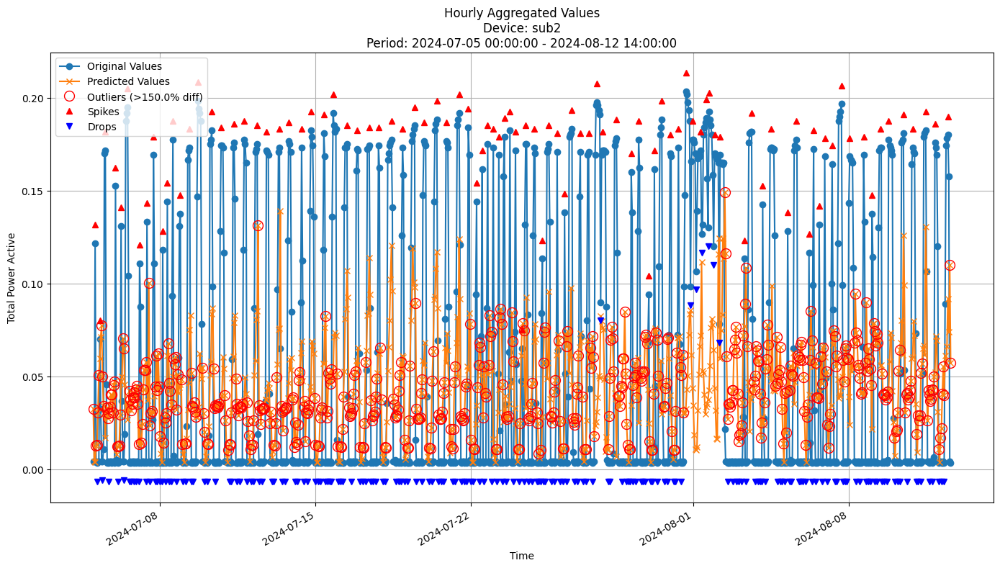


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0699
MAE: 0.0555
MAPE: 559.3082%

Directional Metrics:
Directional Accuracy: 48.5961%
First-Diff Correlation: 0.1069

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


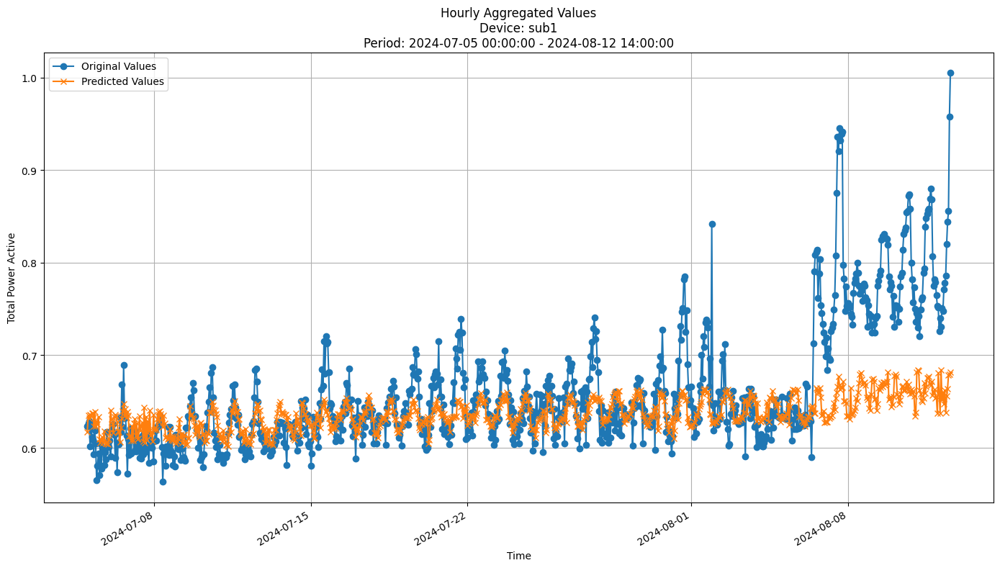


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0610
MAE: 0.0378
MAPE: 5.2232%

Directional Metrics:
Directional Accuracy: 52.6998%
First-Diff Correlation: 0.0692

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


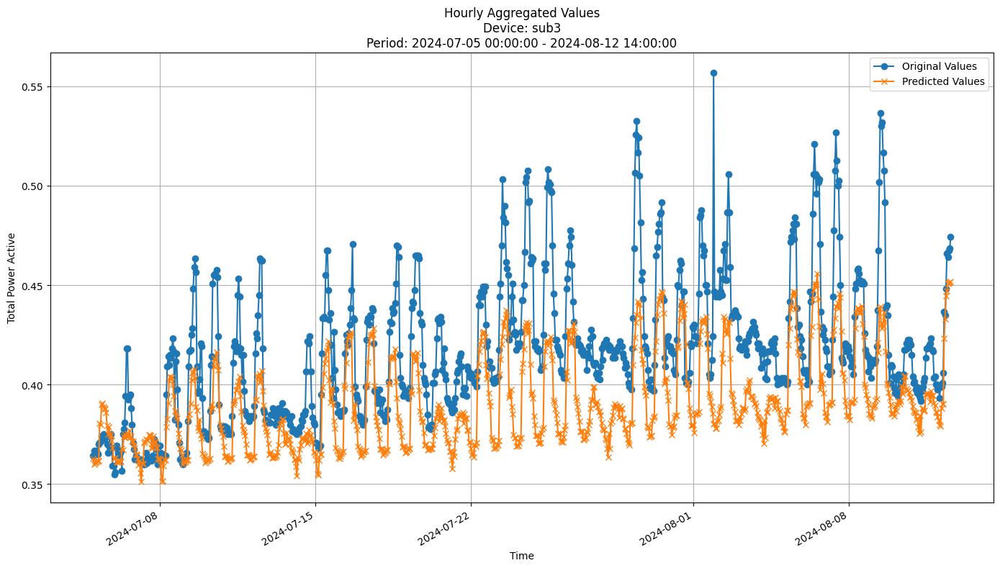


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0333
MAE: 0.0275
MAPE: 6.3563%

Directional Metrics:
Directional Accuracy: 58.8553%
First-Diff Correlation: 0.3830

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [31]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [32]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {'depth': 30, 
               'grace_period': 96, 
               'grace_period_depth': 0, 
               'split_confidence': 0.1, 
               'max_feature': 0.7, 
               'tie_threshold': 0.05, 
               'bin_type': 'adaptive', 
               'max_bins': 16, 
               'split_criterion': 'vr_rel'}

In [33]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 2.855568 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0787
	MAE: 0.0473
	MAPE: 425.4311%

Directional Metrics:
	Directional Accuracy: 47.0939%
	First-Diff Correlation: 0.1821

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1223
		Recall: 0.2361
		F1: 0.1611
	Drops:
		Precision: 0.2215
		Recall: 0.2632
		F1: 0.2405

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4029
		Recall: 0.7778
		F1: 0.5308
	Drops:
		Precision: 0.5380
		Recall: 0.6391
		F1: 0.5842
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 3.794487 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0905
	MAE: 0.0573
	MAPE: 749.6564%

Directional Metrics:
	Directional Accuracy: 48.4252%
	First-Diff Correlation: 0.1041

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2034
		Recall: 0.5000
		F1: 0.2892
	Drops:
		Precision: 0.2381
		Recall: 0.2830
		F1: 0.2586

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3559
		Recall: 0.8750
		F1: 0.5060
	Drops:
		Precision: 0.5556
		Recall: 0.6604
		F1: 0.6034
--------------------------------------------------
Dai

#### Results

In [34]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0796 ± 0.0022
	MAE: 0.0475 ± 0.0012
	MAPE: 574.5115% ± 123.7402%

	Directional Metrics:
		Directional Accuracy: 45.5111% ± 2.5901%
		First-Diff Correlation: 0.0921 ± 0.0465

	Immediate Detection (delta=0):
		Spike Precision: 0.1501 ± 0.0086
		Spike Recall: 0.3205 ± 0.0128
		Spike F1: 0.2041 ± 0.0054
		Drop Precision: 0.2699 ± 0.0217
		Drop Recall: 0.3210 ± 0.0710
		Drop F1: 0.2917 ± 0.0426

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3191 ± 0.0255
		Spike Recall: 0.6904 ± 0.1212
		Spike F1: 0.4356 ± 0.0482
		Drop Precision: 0.5726 ± 0.0113
		Drop Recall: 0.6714 ± 0.0832
		Drop F1: 0.6149 ± 0.0288
Daily Metrics:
	RMSE: 0.5157 ± 0.0102
	MAE: 0.4201 ± 0.0023
	MAPE: 44.2535% ± 2.8521%

	Directional Metrics:
		Directional Accuracy: 44.8485% ± 11.5152%
		First-Diff Correlation: -0.0012 ± 0.3724

	Immediate Detection (delta=0):
	

#### Training plots

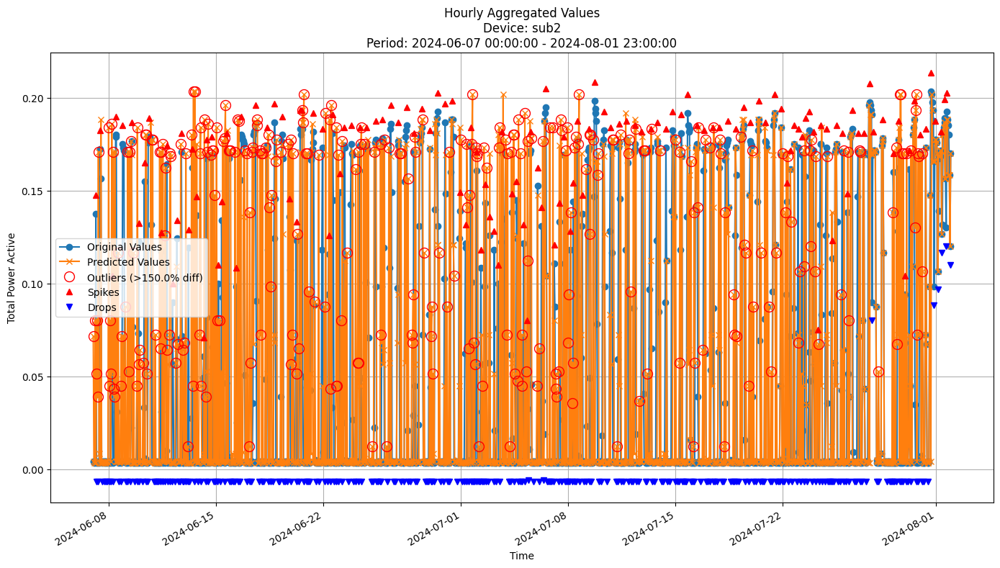


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0818
MAE: 0.0487
MAPE: 698.2517%

Directional Metrics:
Directional Accuracy: 48.1013%
First-Diff Correlation: 0.1386

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1382
  Recall: 0.3066
  F1 Score: 0.1905
Drops:
  Precision: 0.2957
  Recall: 0.3764
  F1 Score: 0.3312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3487
  Recall: 0.7737
  F1 Score: 0.4807
Drops:
  Precision: 0.5623
  Recall: 0.7159
  F1 Score: 0.6299


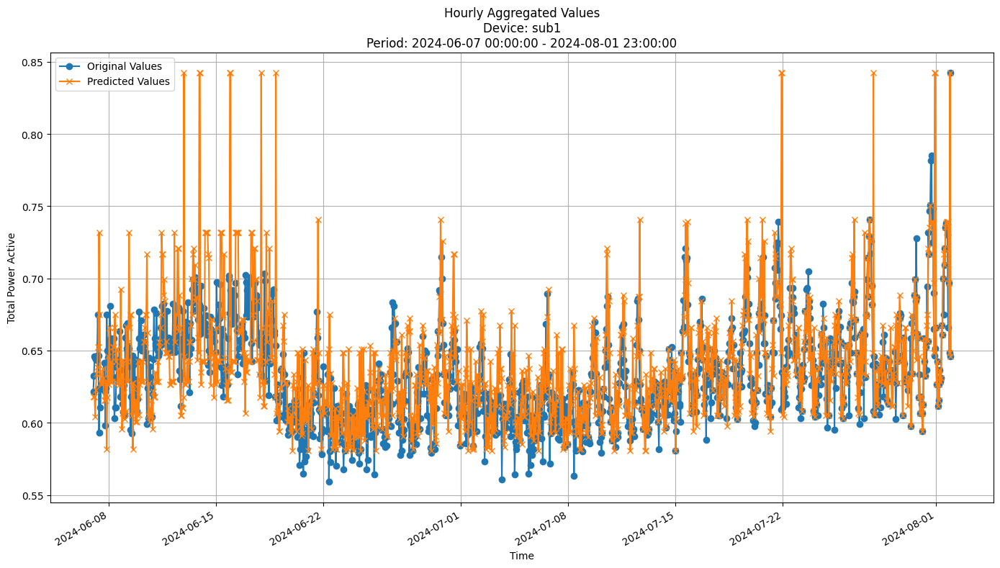


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0336
MAE: 0.0215
MAPE: 3.3994%

Directional Metrics:
Directional Accuracy: 49.9628%
First-Diff Correlation: 0.1852

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


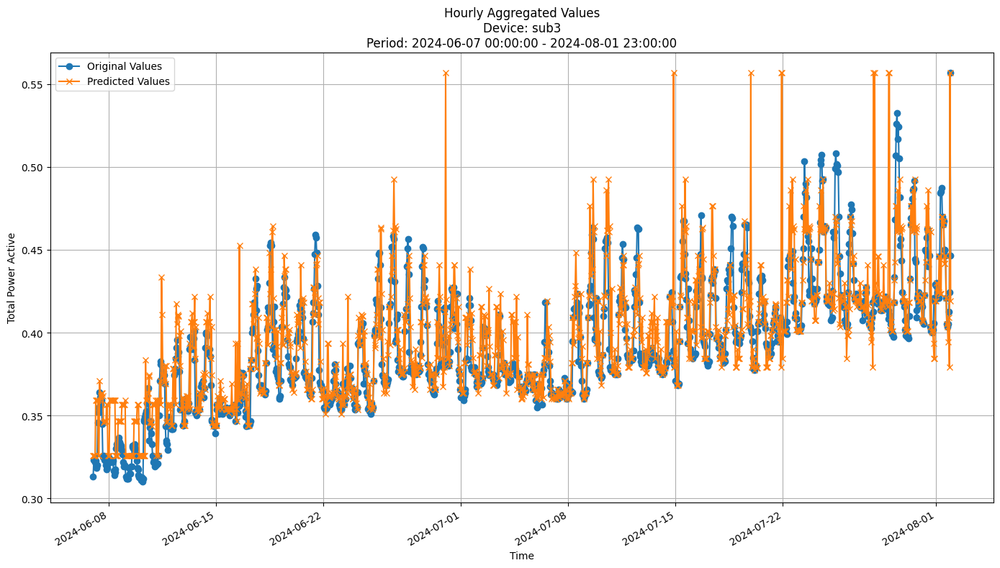


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0235
MAE: 0.0144
MAPE: 3.6473%

Directional Metrics:
Directional Accuracy: 41.9211%
First-Diff Correlation: 0.1641

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [35]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

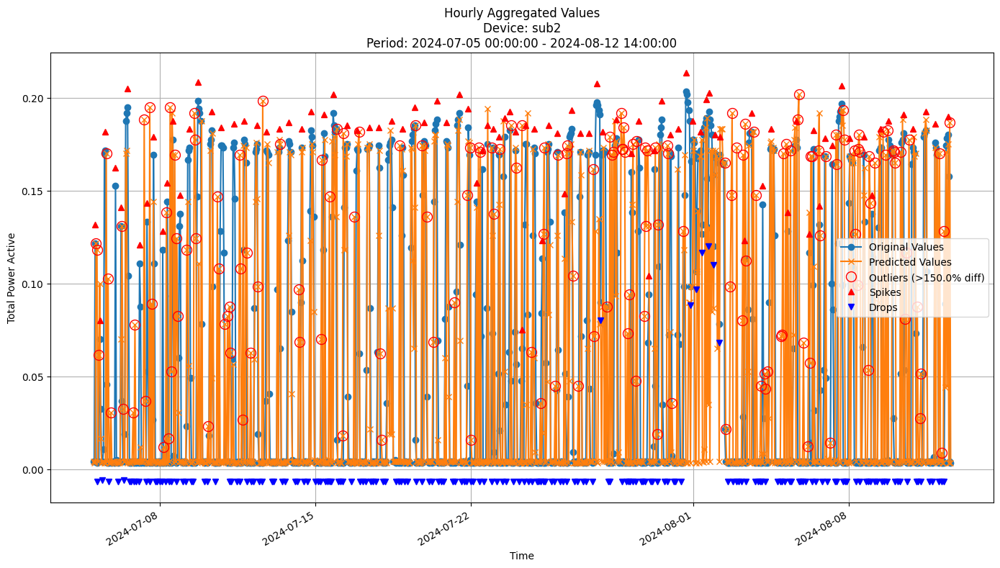


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0821
MAE: 0.0501
MAPE: 514.6193%

Directional Metrics:
Directional Accuracy: 47.4082%
First-Diff Correlation: 0.1589

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1443
  Recall: 0.2917
  F1 Score: 0.1931
Drops:
  Precision: 0.2304
  Recall: 0.2688
  F1 Score: 0.2481

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3918
  Recall: 0.7917
  F1 Score: 0.5241
Drops:
  Precision: 0.5484
  Recall: 0.6398
  F1 Score: 0.5906


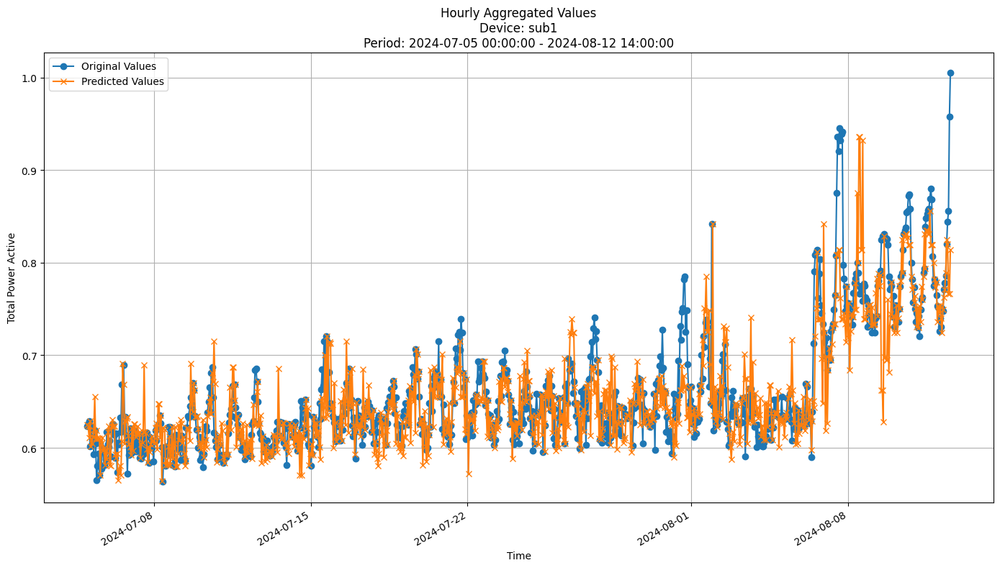


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0393
MAE: 0.0263
MAPE: 3.8624%

Directional Metrics:
Directional Accuracy: 43.3045%
First-Diff Correlation: -0.0736

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


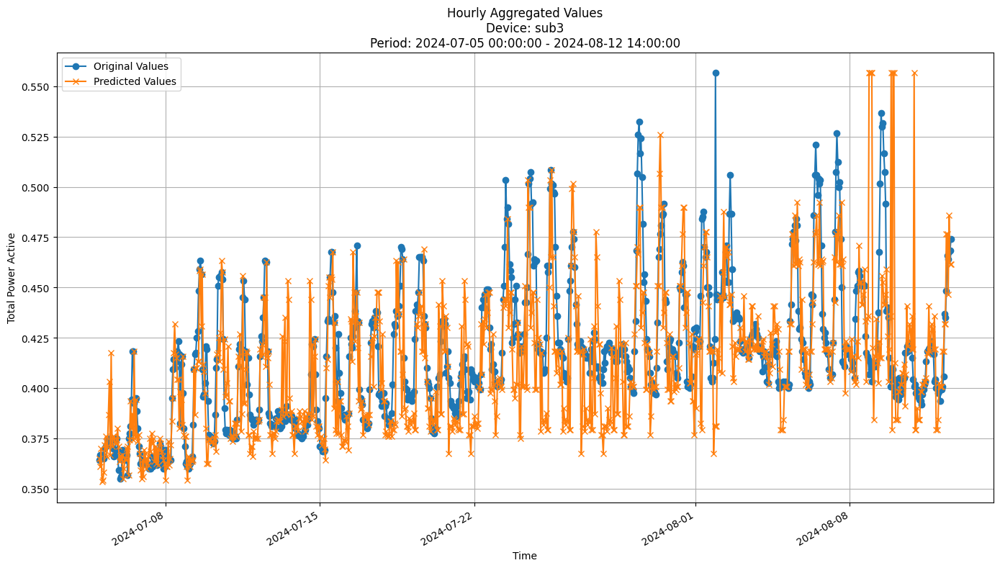


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0287
MAE: 0.0188
MAPE: 4.3720%

Directional Metrics:
Directional Accuracy: 42.4406%
First-Diff Correlation: 0.0559

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
join_periods = [-2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [37]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT

arf_params = {'n_models': 5, 
 'max_features': 0.5, 
 'max_depth': 30, 
 'aggregation_method': 'mean', 
 'disable_weighted_vote': True, 
#  'drift_detector': None, 
#  'warning_detector': None, 
 'eagerness': 0, 
 'tau': 0.05, 
 'delta': 0.05, 
 'grace_period': 96, 
 'grace_period_depth': 0, 
 'bin_type': 'mean', 
 'split_criterion': 'vr_rel'}

# {'depth': 30, 
#                'grace_period': 96, 
#                'grace_period_depth': 0, 
#                'split_confidence': 0.1, 
#                'max_feature': 0.7, 
#                'tie_threshold': 0.05, 
#                'bin_type': 'adaptive', 
#                'max_bins': 16, 
#                'split_criterion': 'vr_rel'}

# arf_params = {
#     "n_models": 20,
#     "aggregation_method": "mean",
#     "grace_period": 0,  # by default works for all leaves
#     "max_depth": 100,
#     "delta": 0.1,  # split confidence
#     "tau": 0.01,  # break ties
#     "seed": 42,
#     "max_features": 0.7,  # maximum feature ratio for each model
# }

In [38]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 12.849915 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0650
	MAE: 0.0450
	MAPE: 484.0529%

Directional Metrics:
	Directional Accuracy: 46.1997%
	First-Diff Correlation: 0.1179

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1139
		Recall: 0.1250
		F1: 0.1192
	Drops:
		Precision: 0.1519
		Recall: 0.0902
		F1: 0.1132

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5696
		Recall: 0.6250
		F1: 0.5960
	Drops:
		Precision: 0.6835
		Recall: 0.4060
		F1: 0.5094
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 17.357521 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0793
	MAE: 0.0576
	MAPE: 723.6342%

Directional Metrics:
	Directional Accuracy: 46.8504%
	First-Diff Correlation: -0.0370

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0294
		Recall: 0.0417
		F1: 0.0345
	Drops:
		Precision: 0.2105
		Recall: 0.1509
		F1: 0.1758

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2353
		Recall: 0.3333
		F1: 0.2759
	Drops:
		Precision: 0.6579
		Recall: 0.4717
		F1: 0.5495
--------------------------------------------------
D

#### Results

In [39]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0751 ± 0.0003
	MAE: 0.0519 ± 0.0012
	MAPE: 690.0721% ± 106.7737%

	Directional Metrics:
		Directional Accuracy: 45.6234% ± 1.2121%
		First-Diff Correlation: 0.0161 ± 0.0481

	Immediate Detection (delta=0):
		Spike Precision: 0.0951 ± 0.0257
		Spike Recall: 0.1037 ± 0.0268
		Spike F1: 0.0992 ± 0.0262
		Drop Precision: 0.2778 ± 0.0383
		Drop Recall: 0.1632 ± 0.0382
		Drop F1: 0.2052 ± 0.0409

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3469 ± 0.0692
		Spike Recall: 0.3785 ± 0.0708
		Spike F1: 0.3620 ± 0.0700
		Drop Precision: 0.6716 ± 0.0238
		Drop Recall: 0.3907 ± 0.0525
		Drop F1: 0.4929 ± 0.0485
Daily Metrics:
	RMSE: 0.4133 ± 0.0411
	MAE: 0.3286 ± 0.0288
	MAPE: 36.1160% ± 6.9735%

	Directional Metrics:
		Directional Accuracy: 49.5286% ± 1.3805%
		First-Diff Correlation: 0.3181 ± 0.2174

	Immediate Detection (delta=0):
		S

#### Training plots

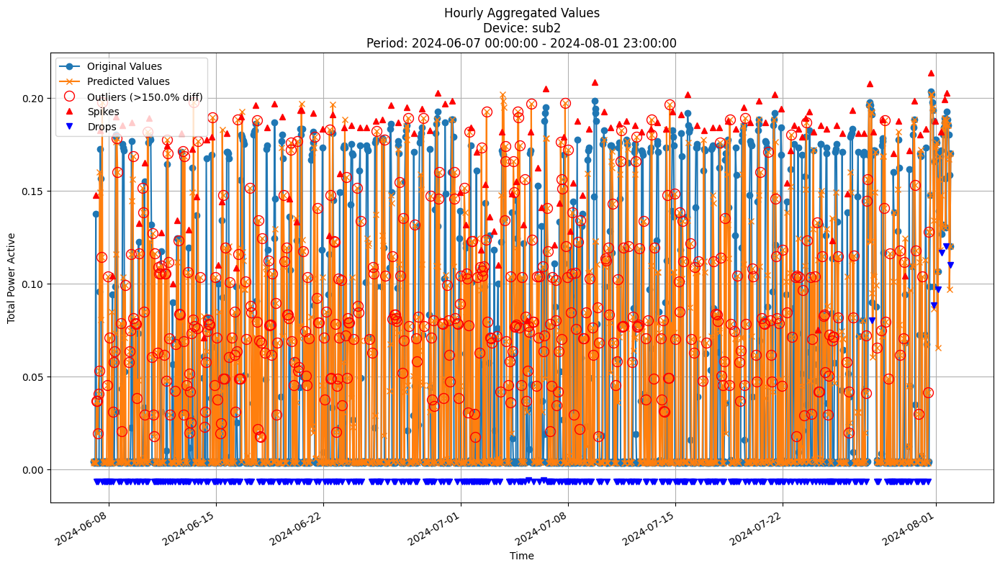


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0754
MAE: 0.0531
MAPE: 796.8458%

Directional Metrics:
Directional Accuracy: 46.8354%
First-Diff Correlation: 0.0642

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


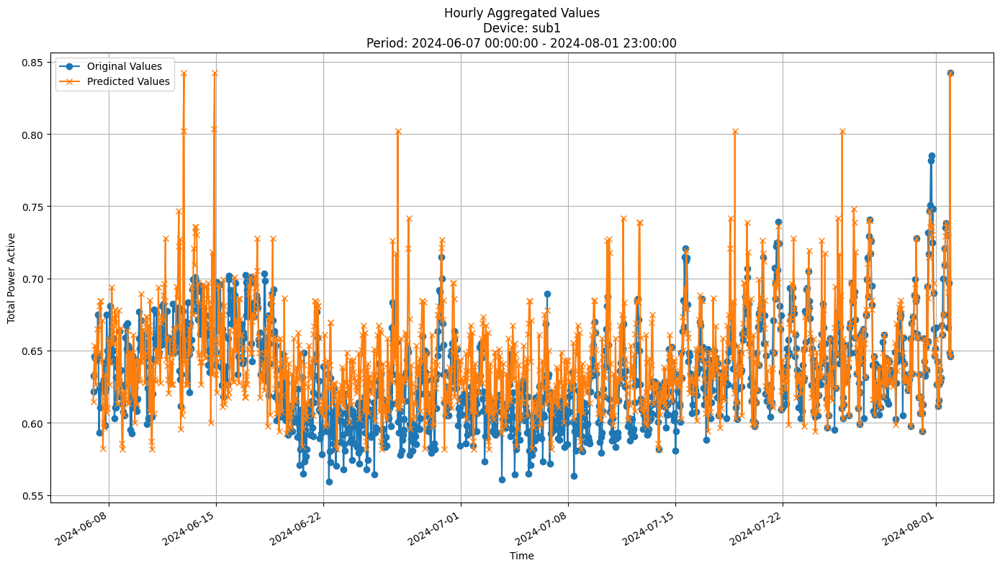


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0325
MAE: 0.0225
MAPE: 3.5997%

Directional Metrics:
Directional Accuracy: 54.5793%
First-Diff Correlation: 0.2604

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


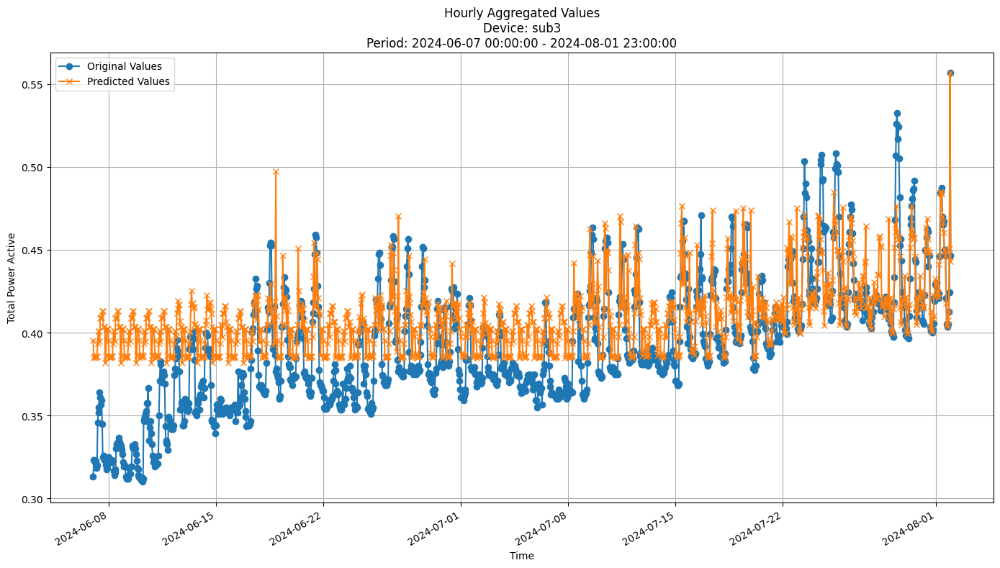


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0319
MAE: 0.0247
MAPE: 6.6414%

Directional Metrics:
Directional Accuracy: 49.0692%
First-Diff Correlation: 0.2687

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [40]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

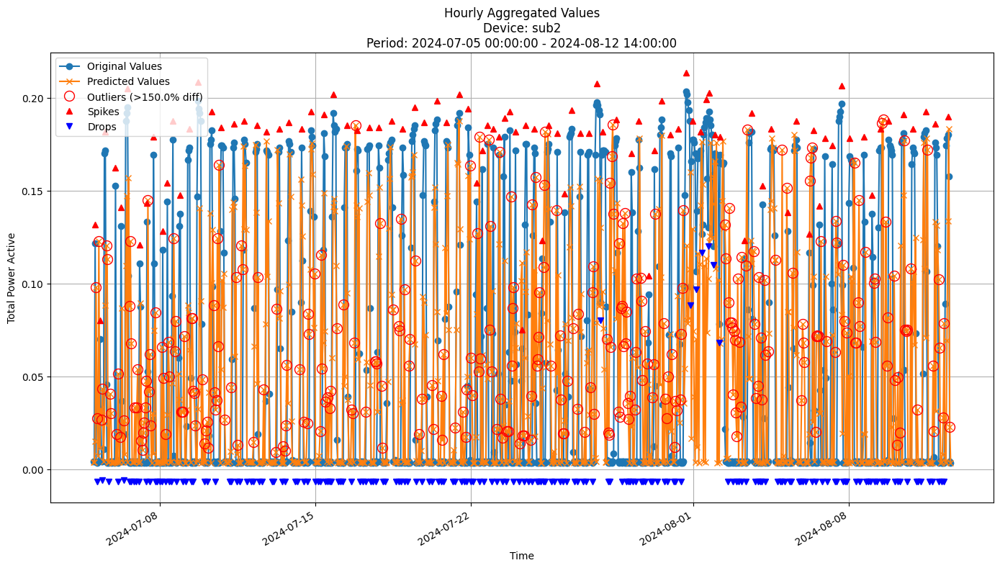


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0692
MAE: 0.0485
MAPE: 549.9572%

Directional Metrics:
Directional Accuracy: 46.4363%
First-Diff Correlation: 0.0721

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


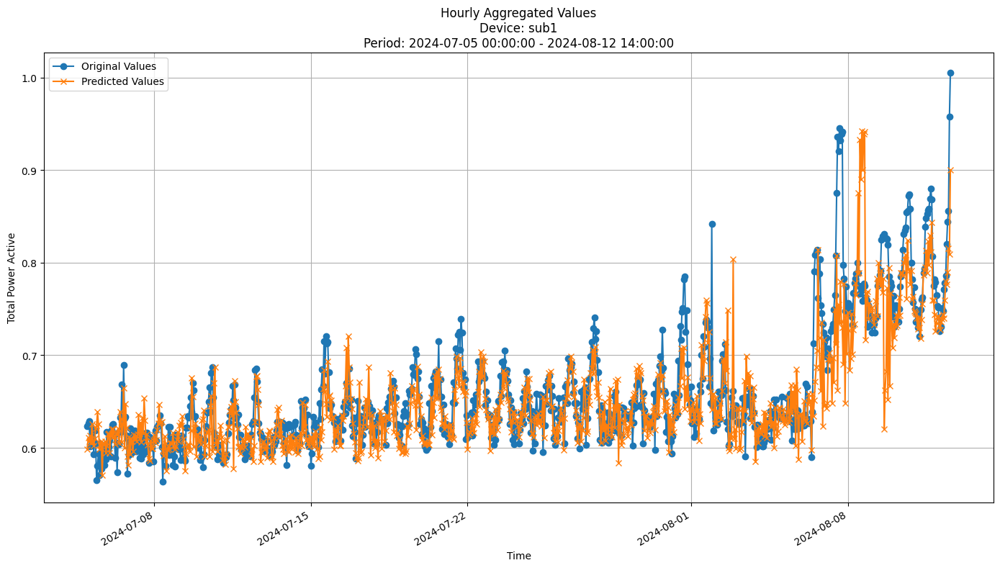


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0395
MAE: 0.0251
MAPE: 3.6210%

Directional Metrics:
Directional Accuracy: 51.9438%
First-Diff Correlation: 0.0706

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


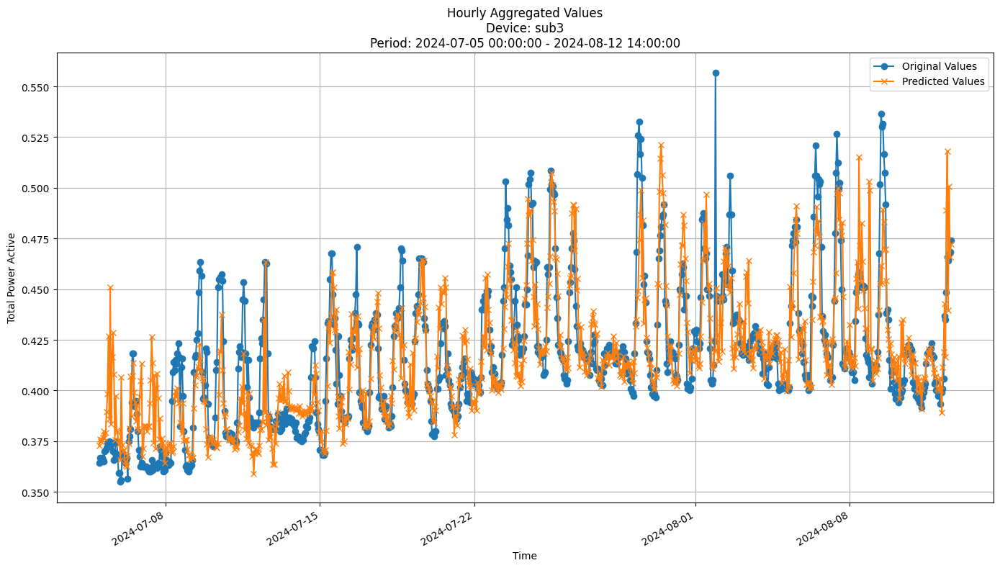


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0204
MAE: 0.0139
MAPE: 3.2629%

Directional Metrics:
Directional Accuracy: 53.2397%
First-Diff Correlation: 0.1564

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [42]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

incb = IncubationBoost

incb_params = {
    'base_learner': fastodt.FastODT, 
    'length': 40, 
    'learning_rate': 0.5, 
    'depth': 10, 
    'grace_period': 0, 
    'grace_period_depth': 1, 
    'split_confidence': 0.05, 
    'max_feature': 1.0, 
    'tie_threshold': 0.01, 
    'bin_type': 'adaptive', 
    'max_bins': 16, 
    'split_criterion': 'vr_rel', 
    'verbose': False}


In [43]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.822792 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1011
	MAE: 0.0688
	MAPE: 522.0332%

Directional Metrics:
	Directional Accuracy: 21.1624%
	First-Diff Correlation: -0.0318

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0575
		Recall: 0.0694
		F1: 0.0629
	Drops:
		Precision: 0.1494
		Recall: 0.0977
		F1: 0.1182

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3218
		Recall: 0.3889
		F1: 0.3522
	Drops:
		Precision: 0.5402
		Recall: 0.3534
		F1: 0.4273
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.870079 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1006
	MAE: 0.0665
	MAPE: 555.9513%

Directional Metrics:
	Directional Accuracy: 27.9528%
	First-Diff Correlation: 0.0867

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1714
		Recall: 0.2500
		F1: 0.2034
	Drops:
		Precision: 0.1471
		Recall: 0.0943
		F1: 0.1149

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2571
		Recall: 0.3750
		F1: 0.3051
	Drops:
		Precision: 0.5588
		Recall: 0.3585
		F1: 0.4368
--------------------------------------------------
Dai

#### Results

In [44]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0926 ± 0.0036
	MAE: 0.0594 ± 0.0035
	MAPE: 569.7378% ± 10.7695%

	Directional Metrics:
		Directional Accuracy: 21.5272% ± 0.5294%
		First-Diff Correlation: 0.0321 ± 0.0224

	Immediate Detection (delta=0):
		Spike Precision: 0.0833 ± 0.0000
		Spike Recall: 0.1046 ± 0.0031
		Spike F1: 0.0927 ± 0.0012
		Drop Precision: 0.2232 ± 0.0268
		Drop Recall: 0.1376 ± 0.0168
		Drop F1: 0.1703 ± 0.0206

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3125 ± 0.0030
		Spike Recall: 0.3920 ± 0.0080
		Spike F1: 0.3477 ± 0.0013
		Drop Precision: 0.6637 ± 0.0387
		Drop Recall: 0.4092 ± 0.0246
		Drop F1: 0.5063 ± 0.0301
Daily Metrics:
	RMSE: 0.4811 ± 0.1431
	MAE: 0.3641 ± 0.0704
	MAPE: 31.7293% ± 1.0393%

	Directional Metrics:
		Directional Accuracy: 0.0000% ± 0.0000%
		First-Diff Correlation: nan ± nan

	Immediate Detection (delta=0):
		Spike Pre

#### Train plots

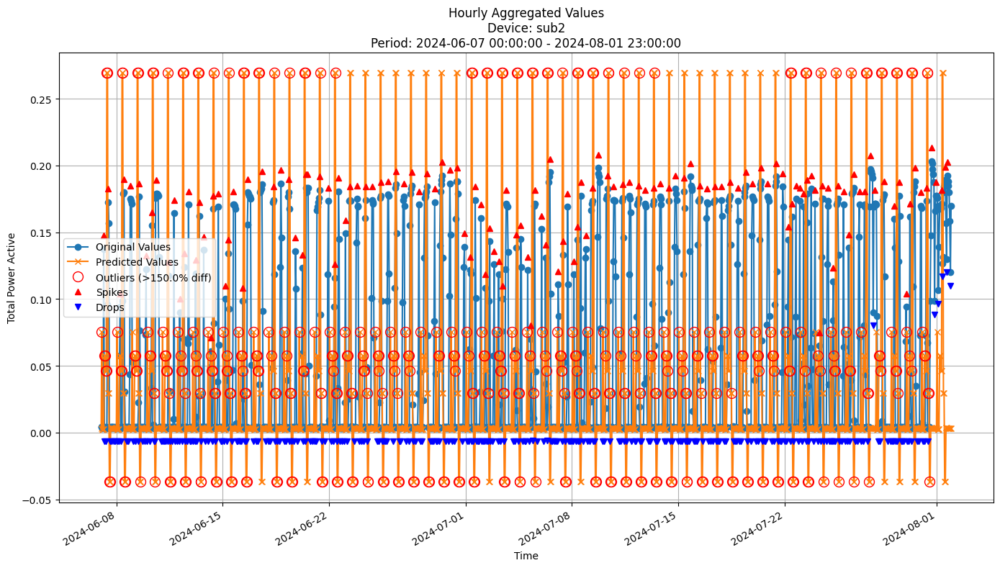


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0961
MAE: 0.0629
MAPE: 558.9683%

Directional Metrics:
Directional Accuracy: 20.9978%
First-Diff Correlation: 0.0097

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0833
  Recall: 0.1022
  F1 Score: 0.0918
Drops:
  Precision: 0.1905
  Recall: 0.1181
  F1 Score: 0.1458

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3155
  Recall: 0.3869
  F1 Score: 0.3475
Drops:
  Precision: 0.6190
  Recall: 0.3838
  F1 Score: 0.4738


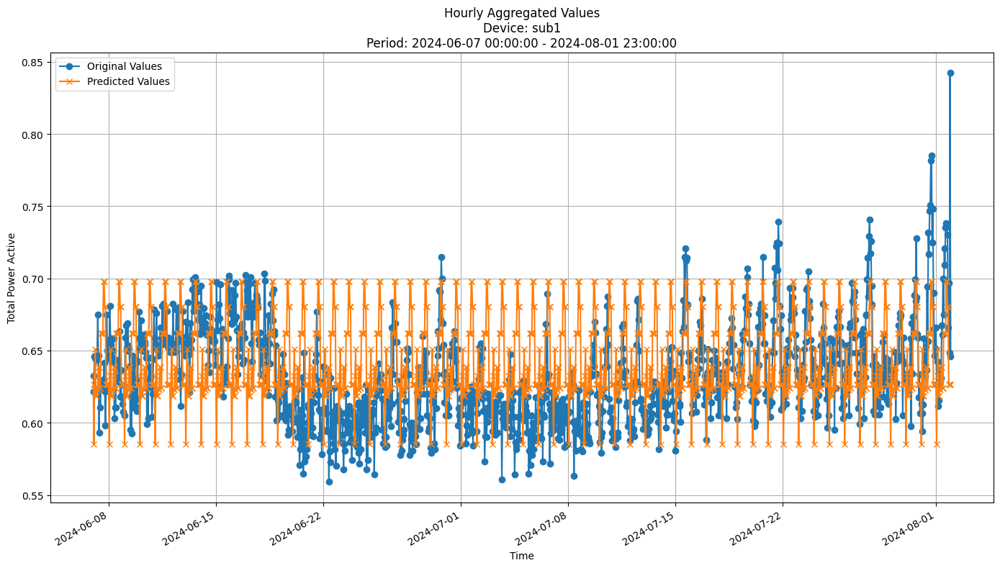


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0391
MAE: 0.0306
MAPE: 4.8756%

Directional Metrics:
Directional Accuracy: 25.6888%
First-Diff Correlation: 0.0343

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


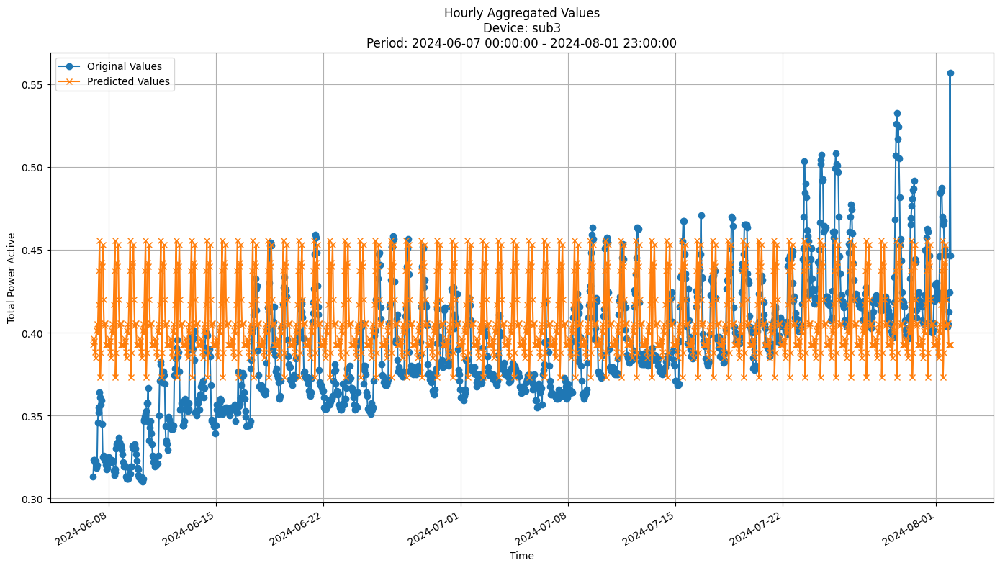


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0418
MAE: 0.0332
MAPE: 8.7475%

Directional Metrics:
Directional Accuracy: 43.8570%
First-Diff Correlation: 0.0239

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [45]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

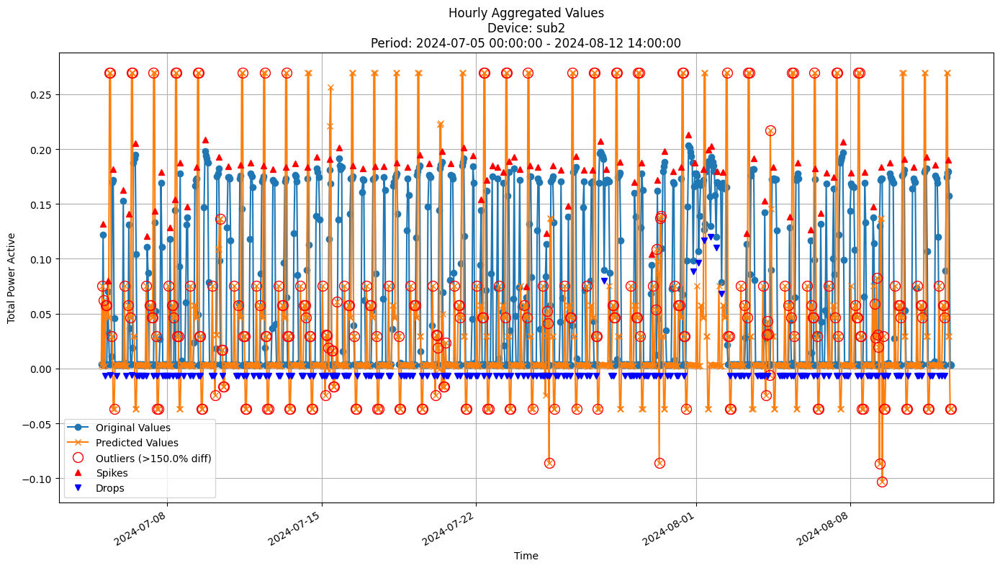


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1010
MAE: 0.0681
MAPE: 531.3634%

Directional Metrics:
Directional Accuracy: 23.0022%
First-Diff Correlation: -0.0003

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0667
  Recall: 0.0625
  F1 Score: 0.0645
Drops:
  Precision: 0.1461
  Recall: 0.0699
  F1 Score: 0.0945

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3000
  Recall: 0.2812
  F1 Score: 0.2903
Drops:
  Precision: 0.6067
  Recall: 0.2903
  F1 Score: 0.3927


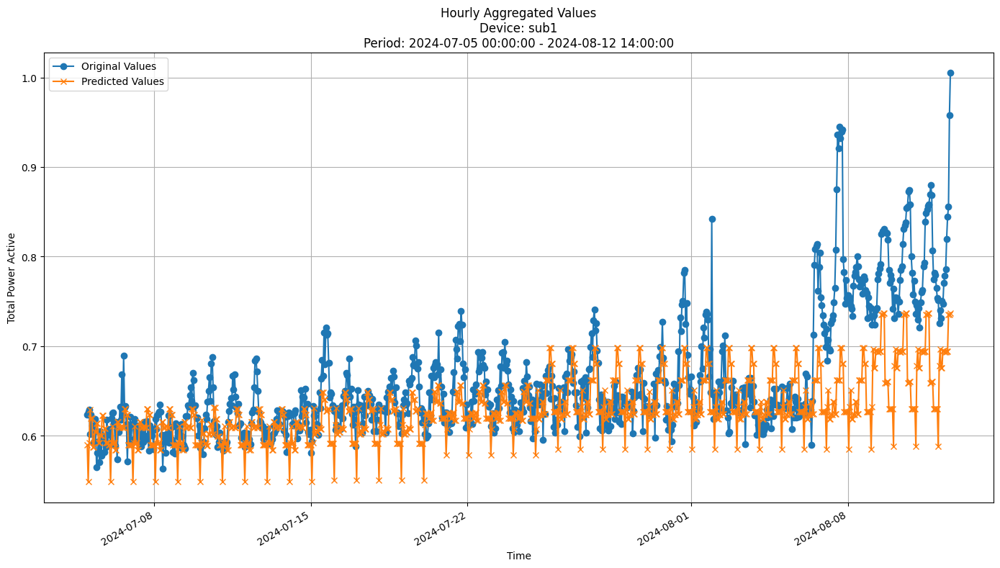


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0611
MAE: 0.0409
MAPE: 5.7520%

Directional Metrics:
Directional Accuracy: 25.5940%
First-Diff Correlation: 0.0279

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


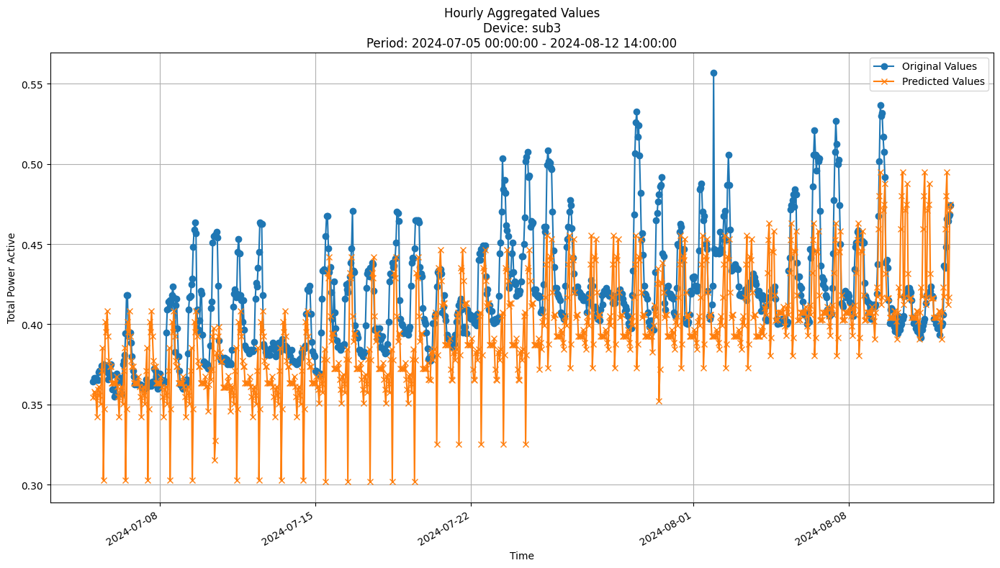


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0403
MAE: 0.0288
MAPE: 6.6573%

Directional Metrics:
Directional Accuracy: 42.3326%
First-Diff Correlation: 0.0724

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
join_periods = [-2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [47]:
# Initialize the models beforehand to run this cell
models_classes = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [baseline_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000374 MB
Metrics for Device: sub1 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0280
	MAE: 0.0174
	MAPE: 1.9633%

Directional Metrics:
	Directional Accuracy: 65.4321%
	First-Diff Correlation: 0.1884

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

Time: 0.14 seconds
Predicting for chunk from 2024-08-12 16:00:00+02:00 to 2024-08-26 16:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-26 16:00:00+02:00

Time: 0.16 seconds
Predicting for chunk from 2024-08-26 17:00:00+02:00 to 2024-08-29 13:00:00+02:00

-------------------------
Model's memory usage: 0.010468 MB
Metrics for Device: sub1 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0707
	MAE: 0.0503
	MAPE: 5.4517%

Directional Metrics:
	Directional Accuracy: 59.0123%
	First-Diff Correlation: 0.1373

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1053
		Recall: 0.1667
		F1: 0.1290
	Drops:
		Precision: 0.0500
		Recall: 0.0769
		F1: 0.0606

Delayed Detection (delta=1 

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 2.966873 MB
Metrics for Device: sub1 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0577
	MAE: 0.0425
	MAPE: 4.7551%

Directional Metrics:
	Directional Accuracy: 54.5679%
	First-Diff Correlation: 0.0374

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0556
		Recall: 0.0833
		F1: 0.0667
	Drops:
		Precision: 0.1667
		Recall: 0.2308
		F1: 0.1935

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1667
		Recall: 0.2500
		F1: 0.2000
	Drops:
		Precision: 0.3889
		Recall: 0.5385
		F1: 0.4516
--------------------------------------------------
Daily

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 3.390732 MB
Metrics for Device: sub1 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1343
	MAE: 0.0979
	MAPE: 10.7072%

Directional Metrics:
	Directional Accuracy: 29.8765%
	First-Diff Correlation: 0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.0833
		F1: 0.1538
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Dail

In [48]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [49]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [50]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [58]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [59]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.028 ± 0.000,0.017 ± 0.000,1.963 ± 0.000,65.432 ± 0.000,18.836 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.071 ± 0.000,0.050 ± 0.000,5.452 ± 0.000,59.012 ± 0.000,13.730 ± 0.000,12.903 ± 0.000,38.710 ± 0.000,6.061 ± 0.000,6.061 ± 0.000
2,RandomForest,0.070 ± 0.000,0.050 ± 0.000,5.391 ± 0.000,60.741 ± 0.000,15.892 ± 0.000,24.242 ± 0.000,42.424 ± 0.000,11.429 ± 0.000,11.429 ± 0.000
3,HoeffdingTree,0.163 ± 0.000,0.143 ± 0.000,15.862 ± 0.000,46.173 ± 0.000,11.051 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
4,ARF_Hoeffding,0.153 ± 0.000,0.115 ± 0.000,12.497 ± 0.000,48.148 ± 0.000,5.529 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,11.111 ± 0.000,11.111 ± 0.000
5,FastODT,0.099 ± 0.000,0.075 ± 0.000,8.332 ± 0.000,48.642 ± 0.000,5.278 ± 0.000,4.000 ± 0.000,4.000 ± 0.000,12.245 ± 0.000,20.408 ± 0.000
6,ARF_FastODT,0.058 ± 0.000,0.043 ± 0.000,4.755 ± 0.000,54.568 ± 0.000,3.739 ± 0.000,6.667 ± 0.000,20.000 ± 0.000,19.355 ± 0.000,45.161 ± 0.000
7,IncubationBoost,0.134 ± 0.000,0.098 ± 0.000,10.707 ± 0.000,29.877 ± 0.000,6.005 ± 0.000,0.000 ± 0.000,15.385 ± 0.000,0.000 ± 0.000,0.000 ± 0.000




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.062 ± 0.000,0.034 ± 0.000,255.408 ± 0.000,45.185 ± 0.000,12.933 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.063 ± 0.000,0.052 ± 0.000,586.755 ± 0.000,55.309 ± 0.000,21.555 ± 0.000,9.302 ± 0.000,51.163 ± 0.000,31.304 ± 0.000,57.391 ± 0.000
2,RandomForest,0.063 ± 0.000,0.050 ± 0.000,531.451 ± 0.000,54.321 ± 0.000,22.701 ± 0.000,12.048 ± 0.000,50.602 ± 0.000,33.929 ± 0.000,55.357 ± 0.000
3,HoeffdingTree,0.069 ± 0.000,0.058 ± 0.000,675.112 ± 0.000,44.691 ± 0.000,14.286 ± 0.000,0.000 ± 0.000,28.169 ± 0.000,12.000 ± 0.000,32.000 ± 0.000
4,ARF_Hoeffding,0.073 ± 0.000,0.062 ± 0.000,672.045 ± 0.000,47.901 ± 0.000,2.290 ± 0.000,7.317 ± 0.000,36.585 ± 0.000,12.613 ± 0.000,37.838 ± 0.000
5,FastODT,0.097 ± 0.000,0.067 ± 0.000,744.770 ± 0.000,42.716 ± 0.000,-0.340 ± 0.000,12.587 ± 0.000,33.566 ± 0.000,25.137 ± 0.000,55.738 ± 0.000
6,ARF_FastODT,0.070 ± 0.000,0.055 ± 0.000,643.103 ± 0.000,48.148 ± 0.000,13.618 ± 0.000,4.545 ± 0.000,31.818 ± 0.000,15.385 ± 0.000,44.444 ± 0.000
7,IncubationBoost,0.107 ± 0.000,0.075 ± 0.000,530.383 ± 0.000,22.222 ± 0.000,-2.337 ± 0.000,13.462 ± 0.000,28.846 ± 0.000,9.023 ± 0.000,31.579 ± 0.000




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.010 ± 0.000,0.006 ± 0.000,1.528 ± 0.000,45.432 ± 0.000,19.885 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.011 ± 0.000,0.008 ± 0.000,2.061 ± 0.000,55.802 ± 0.000,28.930 ± 0.000,0.000 ± 0.000,37.037 ± 0.000,26.667 ± 0.000,46.667 ± 0.000
2,RandomForest,0.012 ± 0.000,0.009 ± 0.000,2.149 ± 0.000,56.049 ± 0.000,25.536 ± 0.000,0.000 ± 0.000,34.483 ± 0.000,12.500 ± 0.000,37.500 ± 0.000
3,HoeffdingTree,0.019 ± 0.000,0.015 ± 0.000,3.805 ± 0.000,47.160 ± 0.000,26.745 ± 0.000,7.692 ± 0.000,7.692 ± 0.000,13.333 ± 0.000,20.000 ± 0.000
4,ARF_Hoeffding,0.015 ± 0.000,0.012 ± 0.000,2.895 ± 0.000,51.605 ± 0.000,48.867 ± 0.000,0.000 ± 0.000,42.857 ± 0.000,0.000 ± 0.000,12.500 ± 0.000
5,FastODT,0.026 ± 0.000,0.015 ± 0.000,3.765 ± 0.000,42.222 ± 0.000,5.959 ± 0.000,10.811 ± 0.000,32.432 ± 0.000,9.091 ± 0.000,27.273 ± 0.000
6,ARF_FastODT,0.017 ± 0.000,0.012 ± 0.000,2.841 ± 0.000,55.802 ± 0.000,24.468 ± 0.000,27.586 ± 0.000,48.276 ± 0.000,6.061 ± 0.000,24.242 ± 0.000
7,IncubationBoost,0.036 ± 0.000,0.028 ± 0.000,6.937 ± 0.000,40.741 ± 0.000,16.764 ± 0.000,12.766 ± 0.000,25.532 ± 0.000,11.765 ± 0.000,35.294 ± 0.000


## Validation results

In [ ]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.025 ± 0.000,0.018 ± 0.001,2.626 ± 0.268,41.266 ± 9.522,-25.975 ± 29.052,0.000 ± 0.000,99.275 ± 0.725,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.038 ± 0.015,0.026 ± 0.009,3.514 ± 0.901,57.333 ± 0.640,21.618 ± 2.703,10.169 ± 10.169,11.864 ± 11.864,5.085 ± 5.085,6.780 ± 6.780
2,RandomForest,0.042 ± 0.018,0.028 ± 0.011,3.829 ± 1.164,54.550 ± 2.976,15.273 ± 8.837,6.557 ± 6.557,8.197 ± 8.197,3.333 ± 3.333,5.000 ± 5.000
3,HoeffdingTree,0.061 ± 0.032,0.049 ± 0.026,6.666 ± 3.082,48.179 ± 6.152,9.394 ± 3.309,2.469 ± 2.469,4.938 ± 4.938,2.532 ± 2.532,10.127 ± 10.127
4,ARF_Hoeffding,0.068 ± 0.039,0.051 ± 0.030,6.838 ± 3.589,52.437 ± 0.469,7.482 ± 1.473,5.479 ± 5.479,15.839 ± 3.339,1.408 ± 1.408,5.634 ± 5.634
5,FastODT,0.043 ± 0.011,0.029 ± 0.006,4.073 ± 0.467,44.364 ± 2.486,-4.353 ± 12.574,1.087 ± 1.087,32.065 ± 7.065,2.222 ± 2.222,15.556 ± 15.556
6,ARF_FastODT,0.044 ± 0.017,0.030 ± 0.010,4.126 ± 1.123,51.012 ± 2.193,7.802 ± 1.750,4.762 ± 4.762,19.048 ± 19.048,0.000 ± 0.000,7.317 ± 7.317
7,IncubationBoost,0.068 ± 0.035,0.053 ± 0.028,7.209 ± 3.238,25.612 ± 0.021,2.796 ± 0.010,6.410 ± 6.410,32.168 ± 13.986,2.597 ± 2.597,12.987 ± 12.987




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.058 ± 0.002,0.031 ± 0.002,243.771 ± 15.178,41.167 ± 1.009,10.417 ± 0.178,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,99.811 ± 0.189
1,GBDT,0.084 ± 0.020,0.070 ± 0.023,1256.344 ± 802.626,51.298 ± 0.117,15.190 ± 9.408,15.597 ± 2.921,48.279 ± 3.834,19.887 ± 2.065,50.398 ± 4.057
2,RandomForest,0.086 ± 0.022,0.072 ± 0.024,1245.123 ± 802.558,49.798 ± 1.767,10.100 ± 16.697,12.960 ± 1.639,39.485 ± 13.070,15.742 ± 3.547,45.605 ± 4.141
3,HoeffdingTree,0.071 ± 0.002,0.056 ± 0.004,615.854 ± 154.610,42.705 ± 2.154,8.693 ± 5.066,2.837 ± 2.837,32.717 ± 16.928,7.867 ± 1.985,28.521 ± 7.932
4,ARF_Hoeffding,0.070 ± 0.001,0.057 ± 0.003,613.666 ± 120.839,47.526 ± 2.250,7.462 ± 7.331,11.455 ± 2.945,38.894 ± 9.106,8.865 ± 0.865,31.423 ± 2.090
5,FastODT,0.085 ± 0.006,0.052 ± 0.005,587.544 ± 162.113,47.760 ± 0.666,14.310 ± 3.903,22.515 ± 6.401,51.841 ± 1.239,24.959 ± 0.904,59.382 ± 0.963
6,ARF_FastODT,0.072 ± 0.007,0.051 ± 0.006,603.844 ± 119.791,46.525 ± 0.325,4.048 ± 7.747,7.684 ± 4.236,43.594 ± 16.008,14.452 ± 3.131,52.944 ± 2.001
7,IncubationBoost,0.101 ± 0.000,0.068 ± 0.001,538.992 ± 16.959,24.558 ± 3.395,2.742 ± 5.926,13.314 ± 7.025,32.864 ± 2.356,11.656 ± 0.162,43.203 ± 0.475




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.012 ± 0.001,0.007 ± 0.000,1.650 ± 0.055,50.953 ± 0.165,24.979 ± 13.119,0.000 ± 0.000,98.936 ± 1.064,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.021 ± 0.001,0.016 ± 0.002,3.742 ± 0.581,53.188 ± 2.401,19.862 ± 2.322,11.930 ± 1.404,33.567 ± 1.988,6.667 ± 6.667,13.651 ± 4.127
2,RandomForest,0.022 ± 0.000,0.017 ± 0.001,3.911 ± 0.356,52.609 ± 5.365,18.880 ± 1.787,13.882 ± 2.118,39.647 ± 4.353,3.922 ± 3.922,24.510 ± 8.824
3,HoeffdingTree,0.034 ± 0.000,0.027 ± 0.001,6.321 ± 0.168,47.935 ± 0.096,17.472 ± 3.687,8.333 ± 8.333,18.089 ± 1.423,0.000 ± 0.000,21.978 ± 6.593
4,ARF_Hoeffding,0.034 ± 0.001,0.028 ± 0.001,6.411 ± 0.121,58.275 ± 1.188,41.421 ± 6.438,10.694 ± 1.806,26.250 ± 13.750,13.333 ± 13.333,23.660 ± 11.895
5,FastODT,0.030 ± 0.005,0.019 ± 0.001,4.448 ± 0.169,41.396 ± 2.419,5.402 ± 0.975,11.792 ± 2.701,22.134 ± 3.953,5.776 ± 2.919,15.839 ± 1.553
6,ARF_FastODT,0.021 ± 0.000,0.014 ± 0.000,3.225 ± 0.084,52.810 ± 0.841,17.887 ± 5.241,13.769 ± 2.231,39.077 ± 7.077,11.547 ± 3.547,38.868 ± 1.132
7,IncubationBoost,0.039 ± 0.003,0.028 ± 0.002,6.345 ± 0.694,43.034 ± 1.454,11.966 ± 9.634,16.444 ± 5.778,39.556 ± 4.889,6.667 ± 6.667,27.619 ± 0.952


: 

### By-period validation results

In [54]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [55]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,31.744,57.973,57.526,42.027,52.906,41.878,53.204,25.633,45.361375
Period 2,50.787,56.693,51.575,54.331,51.969,46.850,48.819,25.591,48.326875



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,19.043,-1.280,-5.951,12.304,-0.937,4.972,-4.385,-0.042,2.966



Device: sub2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,42.176,51.416,51.565,44.858,49.776,47.094,46.200,21.162,44.280875
Period 2,40.157,51.181,48.031,40.551,45.276,48.425,46.850,27.953,43.553000


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,51.118,55.589,57.973,47.839,59.463,43.815,53.651,41.580,51.378500
Period 2,50.787,50.787,47.244,48.031,57.087,38.976,51.969,44.488,48.671125



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.331,-4.802,-10.729,0.192,-2.376,-4.839,-1.682,2.908,-2.707


#### MAPE (lower is better)

In [56]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,2.894,2.613,2.665,3.584,3.248,3.605,3.003,3.970,3.19775
Period 2,2.358,4.414,4.993,9.748,10.427,4.540,5.249,10.447,6.52200



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.536,1.801,2.328,6.164,7.179,0.935,2.246,6.477,3.324



Device: sub2 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,258.949,453.718,442.565,461.244,492.827,425.431,484.053,522.033,442.6025
Period 2,228.593,2058.971,2047.682,770.464,734.505,749.656,723.634,555.951,983.6820


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.704,3.161,3.556,6.153,6.290,4.279,3.309,7.039,4.436375
Period 2,1.595,4.322,4.267,6.489,6.532,4.618,3.141,5.651,4.576875



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.109,1.161,0.711,0.336,0.242,0.339,-0.168,-1.388,0.140


#### RMSE (lower is better)

In [57]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.025,0.024,0.024,0.030,0.029,0.032,0.027,0.033,0.028000
Period 2,0.024,0.053,0.060,0.093,0.106,0.054,0.062,0.103,0.069375



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.029,0.036,0.063,0.077,0.022,0.035,0.070,0.041



Device: sub2 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.060,0.064,0.064,0.070,0.069,0.079,0.065,0.101,0.071500
Period 2,0.056,0.104,0.107,0.073,0.071,0.090,0.079,0.101,0.085125


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.013,0.021,0.022,0.033,0.033,0.026,0.020,0.042,0.02625
Period 2,0.012,0.022,0.022,0.034,0.034,0.035,0.021,0.036,0.02700



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.001,0.000,0.001,0.001,0.009,0.001,-0.006,0.001
